In [23]:
import numpy as np
import pandas as pd
import requests
from concurrent.futures import ThreadPoolExecutor, as_completed

## Load Data


In [24]:
# 2 past seasons + current
past_seasons = ["2024-25", "2025-26"]
current_season = "2026-27"
seasons = past_seasons + [current_season]

target_column = "total_points"
id_column = "element"
time_column = "GW"
random_state = 42

FPL_API = "https://fantasy.premierleague.com/api"
VAASTAV_GW = (
    "https://raw.githubusercontent.com/vaastav/Fantasy-Premier-League/"
    "master/data/{season}/gws/merged_gw.csv"
)
VAASTAV_TEAMS = (
    "https://raw.githubusercontent.com/vaastav/Fantasy-Premier-League/"
    "master/data/{season}/teams.csv"
)
VAASTAV_PLAYERS = (
    "https://raw.githubusercontent.com/vaastav/Fantasy-Premier-League/"
    "master/data/{season}/players_raw.csv"
)
SEASON_ORDER = {"2024-25": 2024, "2025-26": 2025, "2026-27": 2026}
POSITION_MAP = {1: "GK", 2: "DEF", 3: "MID", 4: "FWD"}
K_BY_POSITION = {"GK": 5, "DEF": 10, "MID": 10, "FWD": 10}


In [25]:
def get_json(url):
    response = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=60)
    response.raise_for_status()
    return response.json()


def load_past_season(season):
    data = pd.read_csv(VAASTAV_GW.format(season=season))
    data["season"] = season
    return data


def load_current_season(season):
    bootstrap = get_json(f"{FPL_API}/bootstrap-static/")

    teams = pd.DataFrame(bootstrap["teams"])[["id", "name"]].rename(
        columns={"id": "team_id", "name": "team"}
    )
    players = pd.DataFrame(bootstrap["elements"])[
        ["id", "web_name", "team", "element_type"]
    ].rename(columns={"id": "element", "team": "team_id", "web_name": "name"})
    players["position"] = players["element_type"].map(POSITION_MAP)
    players = players.merge(teams, on="team_id", how="left")

    def fetch_history(element_id):
        summary = get_json(f"{FPL_API}/element-summary/{element_id}/")
        history = pd.DataFrame(summary["history"])
        if history.empty:
            return history
        history["element"] = element_id
        return history

    histories = []
    with ThreadPoolExecutor(max_workers=16) as executor:
        futures = {
            executor.submit(fetch_history, element_id): element_id
            for element_id in players["element"]
        }
        for future in as_completed(futures):
            history = future.result()
            if not history.empty:
                histories.append(history)

    data = pd.concat(histories, ignore_index=True)
    data = data.merge(
        players[["element", "name", "position", "team"]],
        on="element",
        how="left",
    )
    data["GW"] = data["round"]
    data["season"] = season
    data["xP"] = np.nan  # not in live element-summary
    return data, bootstrap


def load_team_lookup(bootstrap):
    frames = []
    for season in past_seasons:
        teams = pd.read_csv(VAASTAV_TEAMS.format(season=season))
        teams = teams[["id", "name"]].rename(
            columns={"id": "team_id", "name": "team_name"}
        )
        teams["season"] = season
        frames.append(teams)

    current = pd.DataFrame(bootstrap["teams"])[["id", "name"]].rename(
        columns={"id": "team_id", "name": "team_name"}
    )
    current["season"] = current_season
    frames.append(current)
    return pd.concat(frames, ignore_index=True)


def load_player_codes(bootstrap):
    frames = []
    for season in past_seasons:
        raw = pd.read_csv(VAASTAV_PLAYERS.format(season=season))
        part = raw[["id", "code"]].drop_duplicates("id")
        part = part.rename(columns={"id": "element"})
        part["season"] = season
        frames.append(part)

    current = pd.DataFrame(bootstrap["elements"])[["id", "code"]].rename(
        columns={"id": "element"}
    )
    current["season"] = current_season
    frames.append(current)
    return pd.concat(frames, ignore_index=True)


In [26]:
past_frames = [load_past_season(season) for season in past_seasons]
current_data, bootstrap = load_current_season(current_season)
team_lookup = load_team_lookup(bootstrap)
player_codes = load_player_codes(bootstrap)

data = pd.concat(past_frames + [current_data], ignore_index=True, sort=False)
data = data.merge(player_codes, on=["season", "element"], how="left")
data = data.sort_values(["season", time_column, id_column]).reset_index(drop=True)

print("Seasons:", seasons)
print("Shape:", data.shape)
print(data.groupby("season")[time_column].agg(["min", "max", "count"]))
display(data.head())
display(data.dtypes)


Seasons: ['2024-25', '2025-26', '2026-27']
Shape: (63924, 55)
         min  max  count
season                  
2024-25    1   38  27605
2025-26    1   38  29757
2026-27    1   10   6562


,name,position,team,xP,assists,bonus,bps,clean_sheets,creativity,element,...,value,was_home,yellow_cards,GW,season,clearances_blocks_interceptions,defensive_contribution,recoveries,tackles,code
0,Fábio Ferreira Vieira,MID,Arsenal,2.3,0,0,0,0,0.0,1,...,55,True,0,1,2024-25,NaN,NaN,NaN,NaN,438098
1,Gabriel Fernando de Jesus,FWD,Arsenal,3.2,0,0,1,0,0.8,2,...,70,True,1,1,2024-25,NaN,NaN,NaN,NaN,205651
2,Gabriel dos Santos Magalhães,DEF,Arsenal,4.2,0,0,22,1,1.4,3,...,60,True,0,1,2024-25,NaN,NaN,NaN,NaN,226597
3,Kai Havertz,FWD,Arsenal,3.5,1,3,48,1,24.1,4,...,80,True,0,1,2024-25,NaN,NaN,NaN,NaN,219847
4,Karl Hein,GK,Arsenal,0.0,0,0,0,0,0.0,5,...,40,True,0,1,2024-25,NaN,NaN,NaN,NaN,463748


name                                object
position                            object
team                                object
xP                                 float64
assists                              int64
bonus                                int64
bps                                  int64
clean_sheets                         int64
creativity                          object
element                              int64
expected_assists                    object
expected_goal_involvements          object
expected_goals                      object
expected_goals_conceded             object
fixture                              int64
goals_conceded                       int64
goals_scored                         int64
ict_index                           object
influence                           object
kickoff_time                        object
minutes                              int64
mng_clean_sheets                   float64
mng_draw                           float64
mng_goals_s

## Basic EDA


Check on full `data` before split:
1) shape / seasons / gameweeks
2) categorical vs numeric columns
3) missing %
4) target (`total_points`) & position mix
5) double gameweeks (player-GW with >1 fixture row)


In [27]:
print("Shape:", data.shape)
print("Seasons:", sorted(data["season"].unique()))
print(data.groupby("season")[time_column].agg(["min", "max", "nunique", "count"]))

display(data.head())
display(data.dtypes)


Shape: (63924, 55)
Seasons: ['2024-25', '2025-26', '2026-27']
         min  max  nunique  count
season                           
2024-25    1   38       38  27605
2025-26    1   38       38  29757
2026-27    1   10       10   6562


,name,position,team,xP,assists,bonus,bps,clean_sheets,creativity,element,...,value,was_home,yellow_cards,GW,season,clearances_blocks_interceptions,defensive_contribution,recoveries,tackles,code
0,Fábio Ferreira Vieira,MID,Arsenal,2.3,0,0,0,0,0.0,1,...,55,True,0,1,2024-25,NaN,NaN,NaN,NaN,438098
1,Gabriel Fernando de Jesus,FWD,Arsenal,3.2,0,0,1,0,0.8,2,...,70,True,1,1,2024-25,NaN,NaN,NaN,NaN,205651
2,Gabriel dos Santos Magalhães,DEF,Arsenal,4.2,0,0,22,1,1.4,3,...,60,True,0,1,2024-25,NaN,NaN,NaN,NaN,226597
3,Kai Havertz,FWD,Arsenal,3.5,1,3,48,1,24.1,4,...,80,True,0,1,2024-25,NaN,NaN,NaN,NaN,219847
4,Karl Hein,GK,Arsenal,0.0,0,0,0,0,0.0,5,...,40,True,0,1,2024-25,NaN,NaN,NaN,NaN,463748


name                                object
position                            object
team                                object
xP                                 float64
assists                              int64
bonus                                int64
bps                                  int64
clean_sheets                         int64
creativity                          object
element                              int64
expected_assists                    object
expected_goal_involvements          object
expected_goals                      object
expected_goals_conceded             object
fixture                              int64
goals_conceded                       int64
goals_scored                         int64
ict_index                           object
influence                           object
kickoff_time                        object
minutes                              int64
mng_clean_sheets                   float64
mng_draw                           float64
mng_goals_s

Check missing %


In [28]:
display(pd.DataFrame({
    "missing_rate": data.isna().mean(),
}).sort_values("missing_rate", ascending=False).head(20))

defensive_columns = [
    c for c in ["tackles", "clearances_blocks_interceptions", "recoveries"]
    if c in data.columns
]
print("Defensive-count missing rate by season:")
display(data.groupby("season")[defensive_columns].agg(lambda s: s.isna().mean()))


,missing_rate
mng_win,0.789954
mng_goals_scored,0.789954
mng_clean_sheets,0.789954
mng_draw,0.789954
mng_underdog_win,0.789954
mng_underdog_draw,0.789954
mng_loss,0.789954
tackles,0.431841
recoveries,0.431841
defensive_contribution,0.431841


Defensive-count missing rate by season:


,tackles,clearances_blocks_interceptions,recoveries
season,,,
2024-25,1.0,1.0,1.0
2025-26,0.0,0.0,0.0
2026-27,0.0,0.0,0.0


Check categorical / non-numeric columns


In [29]:
non_numeric_columns = data.select_dtypes(exclude=["number", "bool"]).columns.tolist()
print("Non-numeric columns:", non_numeric_columns)

for column in ["position", "team", "season"]:
    if column in data.columns:
        print(f"\n{column}:")
        display(data[column].value_counts(dropna=False))


Non-numeric columns: ['name', 'position', 'team', 'creativity', 'expected_assists', 'expected_goal_involvements', 'expected_goals', 'expected_goals_conceded', 'ict_index', 'influence', 'kickoff_time', 'threat', 'season']

position:


position
MID    28482
DEF    21022
FWD     7081
GK      7017
AM       322
Name: count, dtype: int64


team:


team
Brighton          3869
Spurs             3592
Aston Villa       3581
Chelsea           3377
Man Utd           3298
Bournemouth       3256
Crystal Palace    3174
Brentford         3141
Wolves            3102
Newcastle         3036
Nott'm Forest     3011
Liverpool         3005
Man City          2970
Arsenal           2910
Everton           2808
West Ham          2569
Fulham            2561
Sunderland        2105
Leeds             1631
Burnley           1619
Southampton       1484
Leicester         1347
Ipswich           1339
Hull City          419
Coventry City      363
Ipswich Town       357
Name: count, dtype: int64


season:


season
2025-26    29757
2024-25    27605
2026-27     6562
Name: count, dtype: int64

Target distribution (`total_points`) by position


In [30]:
display(data[target_column].describe())
display(
    data.groupby("position")[target_column].describe()
)

# zero-point share (DNP / blanks)
zero_rate = (
    data.assign(is_zero=data[target_column] == 0)
    .groupby("position")["is_zero"]
    .mean()
    .rename("zero_points_rate")
)
display(zero_rate)


count    63924.000000
mean         1.199941
std          2.399110
min         -5.000000
25%          0.000000
50%          0.000000
75%          1.000000
max         25.000000
Name: total_points, dtype: float64

,count,mean,std,min,25%,50%,75%,max
position,,,,,,,,
AM,322.0,5.779503,5.218988,0.0,1.0,5.0,9.0,21.0
DEF,21022.0,1.165588,2.368993,-5.0,0.0,0.0,1.0,24.0
FWD,7081.0,1.321424,2.624645,-2.0,0.0,0.0,1.0,19.0
GK,7017.0,0.830269,1.993606,-3.0,0.0,0.0,0.0,16.0
MID,28482.0,1.234394,2.345430,-2.0,0.0,0.0,2.0,25.0


position
AM     0.220497
DEF    0.622158
FWD    0.579862
GK     0.760011
MID    0.571975
Name: zero_points_rate, dtype: float64

Double gameweeks: >1 fixture row per player-GW


In [31]:
player_gw_counts = (
    data.groupby(["season", id_column, time_column])
    .size()
    .rename("n_fixture_rows")
    .reset_index()
)

print("Rows per player-GW:")
display(player_gw_counts["n_fixture_rows"].value_counts().sort_index())

dgw = player_gw_counts[player_gw_counts["n_fixture_rows"] > 1]
print("DGW player-GW count:", len(dgw))
display(dgw.head())


Rows per player-GW:


n_fixture_rows
1    62338
2      793
Name: count, dtype: int64

DGW player-GW count: 793


,season,element,GW,n_fixture_rows
32,2024-25,1,33,2
69,2024-25,2,33,2
106,2024-25,3,33,2
143,2024-25,4,33,2
180,2024-25,5,33,2


## Next gameweek


In [32]:
# The choice loop uses 2025-26 GW20-38. This cell only finds the finished
# weeks and builds the next gameweek, which has no points yet.
events = pd.DataFrame(bootstrap["events"])[
    ["id", "name", "finished", "is_current", "is_next"]
].rename(columns={"id": "GW"})

# finished = GWs we actually have labels for in current `data`
# (avoids holes when element-summary is ahead/behind bootstrap flags)
finished_gws = (
    data.loc[
        (data["season"] == current_season) & data[target_column].notna(),
        time_column,
    ]
    .drop_duplicates()
    .sort_values()
    .astype(int)
    .tolist()
)

next_gw = events.loc[events["is_next"], "GW"]
test_gw = int(next_gw.iloc[0]) if len(next_gw) else (finished_gws[-1] + 1)

finished_gws = [gw for gw in finished_gws if gw != test_gw]

# upcoming GW may not be in `data` yet (no labels) -> build from fixtures + bootstrap
fixtures = pd.DataFrame(get_json(f"{FPL_API}/fixtures/"))
fixtures = fixtures[fixtures["event"] == test_gw][
    ["id", "event", "team_h", "team_a"]
].rename(columns={"id": "fixture", "event": "GW"})

players = pd.DataFrame(bootstrap["elements"])[
    ["id", "web_name", "team", "element_type", "now_cost"]
].rename(
    columns={
        "id": "element",
        "team": "team_id",
        "web_name": "name",
        "now_cost": "value",
    }
)
teams = pd.DataFrame(bootstrap["teams"])[["id", "name"]].rename(
    columns={"id": "team_id", "name": "team"}
)
players["position"] = players["element_type"].map(POSITION_MAP)
players = players.merge(teams, on="team_id", how="left")

home = fixtures[["fixture", "GW", "team_h", "team_a"]].rename(
    columns={"team_h": "team_id", "team_a": "opponent_team"}
)
home["was_home"] = True
away = fixtures[["fixture", "GW", "team_a", "team_h"]].rename(
    columns={"team_a": "team_id", "team_h": "opponent_team"}
)
away["was_home"] = False
fixture_rows = pd.concat([home, away], ignore_index=True)

test_df = players.merge(fixture_rows, on="team_id", how="inner")
test_df["season"] = current_season
test_df[target_column] = np.nan
test_df = test_df.merge(
    player_codes[["season", "element", "code"]],
    on=["season", "element"],
    how="left",
)

print("Finished GWs (labeled in data):", finished_gws)
print("Test GW:", test_gw)
print("test_df:", test_df.shape, "GW:", sorted(test_df[time_column].unique()))
display(test_df.head())


Finished GWs (labeled in data): [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Test GW: 11
test_df: (672, 14) GW: [np.int64(11)]


,element,name,team_id,element_type,value,position,team,fixture,GW,opponent_team,was_home,season,total_points,code
0,1,Raya,1,1,62,GK,Arsenal,109,11,17,False,2026-27,NaN,154561
1,2,Arrizabalaga,1,1,49,GK,Arsenal,109,11,17,False,2026-27,NaN,109745
2,3,Meslier,1,1,49,GK,Arsenal,109,11,17,False,2026-27,NaN,437495
3,4,Gabriel,1,2,81,DEF,Arsenal,109,11,17,False,2026-27,NaN,226597
4,5,J.Timber,1,2,65,DEF,Arsenal,109,11,17,False,2026-27,NaN,445122


## Feature Engineering


Same `feature_engineer` for every row. A gameweek never sees its own result.

History follows the player `code` across seasons. Team attack and defense rates do the same: the previous five matches can start in the season before. Double gameweeks keep a count of home matches, and they keep the harder opponent band and the easier opponent band.

Team bands use league position only. Past season is the official final table. Current season is the table before that gameweek, and only after the team has already played five matches. Before that, the current band stays at last season's band. A club that was not in the league last season gets past band 0.

Defensive-action counts are missing for 2024-25, so those rows stay missing. Recent minutes is a column. It does not also weight the fit. The fit uses `add_top_group_target`.

The frozen model keeps its original columns. A shadow challenger uses position-specific columns: recent scoring and creation, the defensive-contribution threshold rate, bonus/BPS history, and the team's home/away matchup. Venue rates use only the previous five matches in the same home/away role. For example, an away forward gets his team's away attack against the opponent's home defence.



In [33]:
LEAGUE_EURO_PLACES = {
    # cl, europa, conference from league position only. Cups are ignored,
    # so the conference code is unused on purpose.
    "2023-24": (4, 1, 0),
    "2024-25": (5, 1, 0),
    "2025-26": (5, 1, 0),
    # This season has not earned an extra Champions League place.
    "2026-27": (4, 1, 0),
}

# Official final positions. Names match the vaastav / bootstrap team strings.
FINAL_POSITIONS = {
    "2023-24": {
        "Man City": 1, "Arsenal": 2, "Liverpool": 3, "Aston Villa": 4, "Spurs": 5,
        "Chelsea": 6, "Newcastle": 7, "Man Utd": 8, "West Ham": 9, "Crystal Palace": 10,
        "Brighton": 11, "Bournemouth": 12, "Fulham": 13, "Wolves": 14, "Everton": 15,
        "Brentford": 16, "Nott'm Forest": 17, "Luton": 18, "Burnley": 19, "Sheffield Utd": 20,
    },
    "2024-25": {
        "Liverpool": 1, "Arsenal": 2, "Man City": 3, "Chelsea": 4, "Newcastle": 5,
        "Aston Villa": 6, "Nott'm Forest": 7, "Brighton": 8, "Bournemouth": 9, "Brentford": 10,
        "Fulham": 11, "Crystal Palace": 12, "Everton": 13, "West Ham": 14, "Man Utd": 15,
        "Wolves": 16, "Spurs": 17, "Leicester": 18, "Ipswich": 19, "Southampton": 20,
    },
    "2025-26": {
        "Arsenal": 1, "Man City": 2, "Man Utd": 3, "Aston Villa": 4, "Liverpool": 5,
        "Bournemouth": 6, "Sunderland": 7, "Brighton": 8, "Brentford": 9, "Chelsea": 10,
        "Fulham": 11, "Newcastle": 12, "Everton": 13, "Leeds": 14, "Crystal Palace": 15,
        "Nott'm Forest": 16, "Spurs": 17, "West Ham": 18, "Burnley": 19, "Wolves": 20,
    },
}

PREVIOUS_SEASON = {
    "2024-25": "2023-24",
    "2025-26": "2024-25",
    "2026-27": "2025-26",
}


def band_from_rank(rank, season):
    """7 is Champions League, 0 is not used here. 1 is the bottom of the league."""
    if pd.isna(rank):
        return np.nan
    rank = int(rank)
    champions_league, europa, conference = LEAGUE_EURO_PLACES[season]
    if rank <= champions_league:
        return 7
    if rank <= champions_league + europa:
        return 6
    if rank <= champions_league + europa + conference:
        return 5
    if rank <= 10:
        return 4
    if rank <= 14:
        return 3
    if rank <= 17:
        return 2
    return 1


def past_band_for(team, season):
    """Final band from the previous season. 0 means the club was not in the league."""
    previous = PREVIOUS_SEASON.get(season)
    if previous is None:
        return 0
    rank = FINAL_POSITIONS[previous].get(team)
    if rank is None:
        return 0
    return band_from_rank(rank, previous)


def ranks_from_stats(stats):
    """Points, then goal difference, then goals scored, then name."""
    played = [
        (team, item["pts"], item["gd"], item["gf"])
        for team, item in stats.items()
        if item["played"] > 0
    ]
    played.sort(key=lambda row: (-row[1], -row[2], -row[3], row[0]))
    return {team: rank for rank, (team, *_) in enumerate(played, start=1)}


def build_current_bands(data):
    """Band from this season's table using only matches before that gameweek."""
    scored = data.dropna(subset=["team_h_score", "team_a_score", "team"])
    home = scored.loc[scored["was_home"] == True, [
        "season", time_column, "fixture", "team", "team_h_score", "team_a_score",
    ]]
    home = home.drop_duplicates(["season", "fixture", "team"])
    home = home.rename(columns={"team_h_score": "gf", "team_a_score": "ga"})
    away = scored.loc[scored["was_home"] == False, [
        "season", time_column, "fixture", "team", "team_h_score", "team_a_score",
    ]]
    away = away.drop_duplicates(["season", "fixture", "team"])
    away = away.rename(columns={"team_a_score": "gf", "team_h_score": "ga"})
    matches = pd.concat([home, away], ignore_index=True)
    matches["pts"] = np.where(
        matches["gf"] > matches["ga"], 3, np.where(matches["gf"] == matches["ga"], 1, 0)
    )
    matches["gd"] = matches["gf"] - matches["ga"]

    team_gws = data[["season", time_column, "team"]].dropna().drop_duplicates()
    rows = []
    for season, season_teams in team_gws.groupby("season"):
        teams = sorted(season_teams["team"].unique())
        stats = {team: {"pts": 0, "gd": 0, "gf": 0, "played": 0} for team in teams}
        season_matches = matches[matches["season"] == season]
        for gw in sorted(season_teams[time_column].unique()):
            ranks = ranks_from_stats(stats)
            for team in teams:
                rank = ranks.get(team)
                played_before = stats[team]["played"]
                band = (
                    band_from_rank(rank, season)
                    if rank is not None and played_before >= 5
                    else np.nan
                )
                rows.append({
                    "season": season,
                    time_column: gw,
                    "team": team,
                    "team_current_band": band,
                })
            played_now = season_matches[season_matches[time_column] == gw]
            for record in played_now.itertuples(index=False):
                item = stats[record.team]
                item["pts"] += record.pts
                item["gd"] += record.gd
                item["gf"] += record.gf
                item["played"] += 1
    return pd.DataFrame(rows)


def build_team_gw(data):
    """Team goals and goals-against per gameweek, from that gameweek's matches."""
    match_xg = (
        data.groupby(["season", time_column, "fixture", "team"], as_index=False)[
            "expected_goals"
        ]
        .sum()
        .rename(columns={"expected_goals": "match_xg"})
    )
    pairs = data.groupby(
        ["season", time_column, "fixture", "team", "opponent_name"], as_index=False
    ).size()
    pairs = pairs.drop(columns="size")
    pairs = pairs.merge(
        match_xg, on=["season", time_column, "fixture", "team"], how="left"
    )
    opponent_xg = match_xg.rename(
        columns={"team": "opponent_name", "match_xg": "opp_xg"}
    )
    pairs = pairs.merge(
        opponent_xg,
        on=["season", time_column, "fixture", "opponent_name"],
        how="left",
    )
    return pairs.groupby(["season", time_column, "team"], as_index=False).agg(
        team_xg=("match_xg", "sum"),
        team_xga=("opp_xg", "sum"),
        team_n_fixtures=("fixture", "nunique"),
    )


def add_team_rates(team_gw):
    """Previous 5 matches. The window continues from the previous season."""
    team_gw = team_gw.copy()
    team_gw["season_order"] = team_gw["season"].map(SEASON_ORDER)
    team_gw = team_gw.sort_values(["team", "season_order", time_column]).reset_index(drop=True)
    grouped = team_gw.groupby("team", sort=False)

    def previous_rate(value_column):
        numerator = grouped[value_column].transform(
            lambda s: s.shift(1).rolling(5, min_periods=1).sum()
        )
        denominator = grouped["team_n_fixtures"].transform(
            lambda s: s.shift(1).rolling(5, min_periods=1).sum()
        )
        return numerator / denominator.replace(0, np.nan)

    team_gw["team_xg_per_match_5"] = previous_rate("team_xg")
    team_gw["team_xga_per_match_5"] = previous_rate("team_xga")

    league = team_gw.groupby(["season", time_column])[
        ["team_xg_per_match_5", "team_xga_per_match_5"]
    ].transform("mean")
    team_gw["xg_rate"] = team_gw["team_xg_per_match_5"] / league["team_xg_per_match_5"]
    team_gw["xga_rate"] = team_gw["team_xga_per_match_5"] / league["team_xga_per_match_5"]
    return team_gw.drop(columns="season_order")


def player_opponent_rates(data, team_gw):
    """Average the upcoming opponents' pre-gameweek rates. Double gameweeks are averaged."""
    rates = team_gw.rename(
        columns={
            "team": "opponent_name",
            "xg_rate": "opp_xg_rate",
            "xga_rate": "opp_xga_rate",
        }
    )
    long = data[
        ["season", id_column, time_column, "fixture", "opponent_name"]
    ].drop_duplicates()
    long = long.merge(
        rates[["season", time_column, "opponent_name", "opp_xg_rate", "opp_xga_rate"]],
        on=["season", time_column, "opponent_name"],
        how="left",
    )
    return long.groupby(["season", id_column, time_column], as_index=False)[
        ["opp_xg_rate", "opp_xga_rate"]
    ].mean()


def build_team_fixture(data):
    """One row per team-fixture with xG, xGA, venue, and the actual clean-sheet result."""
    data = data.copy()
    data["expected_goals"] = pd.to_numeric(data["expected_goals"], errors="coerce")
    match_xg = (
        data.groupby(["season", time_column, "fixture", "team"], as_index=False)[
            "expected_goals"
        ]
        .sum(min_count=1)
        .rename(columns={"expected_goals": "team_xg"})
    )
    fixture_team = data[[
        "season", time_column, "fixture", "team", "opponent_name", "was_home",
        "team_h_score", "team_a_score",
    ]].drop_duplicates(["season", "fixture", "team"])
    fixture_team = fixture_team.merge(
        match_xg, on=["season", time_column, "fixture", "team"], how="left"
    )
    opponent_xg = match_xg.rename(
        columns={"team": "opponent_name", "team_xg": "team_xga"}
    )
    fixture_team = fixture_team.merge(
        opponent_xg,
        on=["season", time_column, "fixture", "opponent_name"],
        how="left",
    )
    fixture_team["goals_against"] = np.where(
        fixture_team["was_home"],
        fixture_team["team_a_score"],
        fixture_team["team_h_score"],
    )
    fixture_team["team_clean_sheet"] = np.where(
        fixture_team["goals_against"].notna(),
        (fixture_team["goals_against"] == 0).astype(float),
        np.nan,
    )
    return fixture_team


def add_team_venue_rates(team_fixture):
    """Previous five same-venue matches. Fixtures in one GW share the same prior history."""
    team_fixture = team_fixture.copy()
    team_fixture["season_order"] = team_fixture["season"].map(SEASON_ORDER)
    team_fixture = team_fixture.sort_values(
        ["team", "was_home", "season_order", time_column, "fixture"]
    ).reset_index(drop=True)
    rate_columns = {
        "team_xg": "team_xg_venue_5",
        "team_xga": "team_xga_venue_5",
        "team_clean_sheet": "team_clean_sheet_venue_rate_5",
    }
    for target in rate_columns.values():
        team_fixture[target] = np.nan

    for _, group in team_fixture.groupby(["team", "was_home"], sort=False):
        history = {source: [] for source in rate_columns}
        for _, gw_part in group.groupby(["season_order", time_column], sort=False):
            for source, target in rate_columns.items():
                values = history[source][-5:]
                if values:
                    team_fixture.loc[gw_part.index, target] = float(np.mean(values))
            for source in rate_columns:
                current = gw_part[source].dropna().astype(float).tolist()
                history[source].extend(current)

    return team_fixture.drop(columns="season_order")


def player_venue_matchups(data, team_fixture):
    """Pre-game venue attack and defence for each player-fixture, then one player-GW row."""
    keys = ["season", time_column, "fixture"]
    own_columns = [
        "team_xg_venue_5", "team_xga_venue_5", "team_clean_sheet_venue_rate_5",
    ]
    fixture_rows = data[
        keys + [id_column, "team", "opponent_name"]
    ].drop_duplicates()
    fixture_rows = fixture_rows.merge(
        team_fixture[keys + ["team"] + own_columns],
        on=keys + ["team"],
        how="left",
    )
    opponent = team_fixture[keys + ["team", "team_xg_venue_5", "team_xga_venue_5"]].rename(
        columns={
            "team": "opponent_name",
            "team_xg_venue_5": "opp_xg_venue_5",
            "team_xga_venue_5": "opp_xga_venue_5",
        }
    )
    fixture_rows = fixture_rows.merge(
        opponent, on=keys + ["opponent_name"], how="left"
    )
    fixture_rows["venue_attack_matchup"] = (
        fixture_rows["team_xg_venue_5"] * fixture_rows["opp_xga_venue_5"]
    )
    fixture_rows["venue_defense_matchup"] = (
        fixture_rows["team_xga_venue_5"] * fixture_rows["opp_xg_venue_5"]
    )
    value_columns = own_columns + [
        "opp_xg_venue_5", "opp_xga_venue_5",
        "venue_attack_matchup", "venue_defense_matchup",
    ]
    return fixture_rows.groupby(
        ["season", id_column, time_column], as_index=False
    )[value_columns].mean()


def feature_engineer(data, beta=0.9):
    """X-side only. History uses earlier rows of the same player, including past seasons."""
    data = data.copy()

    drop_columns = [c for c in data.columns if c.startswith("mng_")]
    data = data.drop(columns=drop_columns, errors="ignore")

    numeric_object_columns = [
        "creativity", "influence", "threat", "ict_index",
        "expected_goals", "expected_assists", "expected_goal_involvements",
        "expected_goals_conceded", "xP",
    ]
    for column in numeric_object_columns:
        if column in data.columns:
            data[column] = pd.to_numeric(data[column], errors="coerce")

    if "position" in data.columns:
        data["position"] = data["position"].replace({"AM": "MID"})

    data["season_order"] = data["season"].map(SEASON_ORDER)
    data["player_key"] = np.where(
        data["code"].notna(),
        "code-" + data["code"].astype("Int64").astype(str),
        data["season"].astype(str) + "-" + data[id_column].astype(str),
    )

    lookup = team_lookup.rename(
        columns={"team_id": "opponent_team", "team_name": "opponent_name"}
    )
    data = data.drop(columns=["opponent_name"], errors="ignore")
    data = data.merge(
        lookup[["season", "opponent_team", "opponent_name"]],
        on=["season", "opponent_team"],
        how="left",
    )

    band_table = build_current_bands(data)
    band_table["team_past_band"] = [
        past_band_for(team, season)
        for team, season in zip(band_table["team"], band_table["season"])
    ]
    band_table["team_current_band"] = band_table["team_current_band"].fillna(
        band_table["team_past_band"]
    )

    opponent_bands = band_table.rename(
        columns={
            "team": "opponent_name",
            "team_past_band": "opp_past_band",
            "team_current_band": "opp_current_band",
        }
    )
    long_opponents = data[
        ["season", id_column, time_column, "fixture", "opponent_name"]
    ].drop_duplicates()
    long_opponents = long_opponents.merge(
        opponent_bands[
            ["season", time_column, "opponent_name", "opp_past_band", "opp_current_band"]
        ],
        on=["season", time_column, "opponent_name"],
        how="left",
    )
    # a double keeps the harder band and the easier band
    opponent_band_span = long_opponents.groupby(
        ["season", id_column, time_column], as_index=False
    ).agg(
        opp_past_band_hard=("opp_past_band", "max"),
        opp_past_band_easy=("opp_past_band", "min"),
        opp_current_band_hard=("opp_current_band", "max"),
        opp_current_band_easy=("opp_current_band", "min"),
    )

    team_gw = add_team_rates(build_team_gw(data))
    opponent_rates = player_opponent_rates(data, team_gw)
    team_fixture = add_team_venue_rates(build_team_fixture(data))
    venue_matchups = player_venue_matchups(data, team_fixture)

    # Fixture-level threshold events are calculated before double gameweeks collapse.
    data["n_fixtures"] = 1
    data["n_home"] = data["was_home"].fillna(False).astype(int)
    defender_parts = [
        c for c in ["tackles", "clearances_blocks_interceptions"] if c in data.columns
    ]
    outfield_parts = [
        c for c in ["tackles", "clearances_blocks_interceptions", "recoveries"]
        if c in data.columns
    ]
    defender_count = data[defender_parts].sum(axis=1, min_count=1)
    outfield_count = data[outfield_parts].sum(axis=1, min_count=1)
    fixture_def_count = pd.Series(
        np.where(data["position"] == "DEF", defender_count, outfield_count),
        index=data.index,
        dtype=float,
    )
    def_threshold = data["position"].map({"DEF": 10, "MID": 12, "FWD": 12})
    data["def_contribution_hit"] = np.nan
    known_def = fixture_def_count.notna() & def_threshold.notna()
    data.loc[known_def, "def_contribution_hit"] = (
        fixture_def_count.loc[known_def] >= def_threshold.loc[known_def]
    ).astype(float)
    data["bonus_hit"] = np.where(
        data["bonus"].notna(), (data["bonus"] > 0).astype(float), np.nan
    )
    data["eligible_clean_sheet_hit"] = np.where(
        data["clean_sheets"].notna() & data["minutes"].notna(),
        ((data["clean_sheets"] > 0) & (data["minutes"] >= 60)).astype(float),
        np.nan,
    )

    # one row per player-gameweek
    group_keys = ["season", id_column, time_column]
    sum_columns = [
        c
        for c in [
            "minutes", "total_points", "assists", "bonus", "bps", "clean_sheets",
            "goals_conceded", "goals_scored", "own_goals", "penalties_missed",
            "penalties_saved", "saves", "yellow_cards", "red_cards", "starts",
            "expected_goals", "expected_assists", "expected_goal_involvements",
            "expected_goals_conceded", "influence", "creativity", "threat", "ict_index",
            "clearances_blocks_interceptions", "recoveries", "tackles",
            "defensive_contribution", "def_contribution_hit", "bonus_hit",
            "eligible_clean_sheet_hit", "transfers_in", "transfers_out",
            "transfers_balance", "selected", "n_fixtures", "n_home",
        ]
        if c in data.columns
    ]
    first_columns = [
        c
        for c in [
            "name", "position", "team", "value", "code", "player_key", "season_order",
        ]
        if c in data.columns
    ]
    def sum_keep_missing(series):
        return series.sum(min_count=1)

    agg = {c: sum_keep_missing for c in sum_columns}
    agg.update({c: "first" for c in first_columns})
    data = data.groupby(group_keys, as_index=False).agg(agg)

    data = data.merge(
        band_table[
            ["season", time_column, "team", "team_past_band", "team_current_band"]
        ],
        on=["season", time_column, "team"],
        how="left",
    )
    data = data.merge(
        opponent_band_span, on=["season", id_column, time_column], how="left"
    )

    # player history across seasons, past rows only
    data = data.sort_values(["player_key", "season_order", time_column]).reset_index(drop=True)
    player_group = data.groupby("player_key", sort=False)

    data["minutes_ewm"] = player_group["minutes"].transform(
        lambda s: s.ewm(alpha=1 - beta, adjust=True).mean().shift(1)
    )
    data["zero_min_rate_5"] = player_group["minutes"].transform(
        lambda s: (s == 0).astype(float).shift(1).rolling(5, min_periods=1).mean()
    )
    start_share = data["starts"].fillna(0) / data["n_fixtures"]
    data["start_rate_5"] = start_share.groupby(data["player_key"], sort=False).transform(
        lambda s: s.shift(1).rolling(5, min_periods=1).mean()
    )
    full_share = data["minutes"].fillna(0) / data["n_fixtures"]
    data["minutes_60_rate"] = (full_share >= 60).astype(float).groupby(
        data["player_key"], sort=False
    ).transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())

    def history_per90(column, skip_missing=False):
        value = pd.to_numeric(data[column], errors="coerce")
        minutes = data["minutes"].fillna(0.0)
        if skip_missing:
            minutes = minutes.where(value.notna(), 0.0)
        value = value.fillna(0.0)
        temp = pd.DataFrame({"player_key": data["player_key"], "_value": value, "_minutes": minutes})
        grouped = temp.groupby("player_key", sort=False)
        cum_value = grouped["_value"].transform(lambda s: s.cumsum().shift(1))
        cum_minutes = grouped["_minutes"].transform(lambda s: s.cumsum().shift(1))
        return np.where(cum_minutes > 0, cum_value / cum_minutes * 90.0, np.nan)

    def recent_per90(column, window):
        value = pd.to_numeric(data[column], errors="coerce").fillna(0.0)
        minutes = data["minutes"].fillna(0.0)
        temp = pd.DataFrame({"player_key": data["player_key"], "_value": value, "_minutes": minutes})
        grouped = temp.groupby("player_key", sort=False)
        roll_value = grouped["_value"].transform(
            lambda s: s.shift(1).rolling(window, min_periods=1).sum()
        )
        roll_minutes = grouped["_minutes"].transform(
            lambda s: s.shift(1).rolling(window, min_periods=1).sum()
        )
        return np.where(roll_minutes > 0, roll_value / roll_minutes * 90.0, np.nan)

    data["xg_per90"] = history_per90("expected_goals") if "expected_goals" in data.columns else np.nan
    data["xa_per90"] = history_per90("expected_assists") if "expected_assists" in data.columns else np.nan
    data["saves_per90"] = history_per90("saves") if "saves" in data.columns else np.nan
    data["xg_per90_5"] = recent_per90("expected_goals", 5)
    data["xa_per90_5"] = recent_per90("expected_assists", 5)
    data["xg_per90_10"] = recent_per90("expected_goals", 10)
    data["xa_per90_10"] = recent_per90("expected_assists", 10)
    data["goals_per90_10"] = recent_per90("goals_scored", 10)
    data["assists_per90_10"] = recent_per90("assists", 10)
    data["threat_per90_5"] = recent_per90("threat", 5)
    data["creativity_per90_5"] = recent_per90("creativity", 5)
    data["saves_per90_5"] = recent_per90("saves", 5)
    data["bps_per90_5"] = recent_per90("bps", 5)
    data["xg_form"] = data["xg_per90_5"] - data["xg_per90"]
    data["xa_form"] = data["xa_per90_5"] - data["xa_per90"]

    bonus_share = data["bonus_hit"] / data["n_fixtures"].replace(0, np.nan)
    data["bonus_rate_5"] = bonus_share.groupby(
        data["player_key"], sort=False
    ).transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    clean_sheet_share = (
        data["eligible_clean_sheet_hit"] / data["n_fixtures"].replace(0, np.nan)
    )
    data["clean_sheet_rate_5"] = clean_sheet_share.groupby(
        data["player_key"], sort=False
    ).transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())

    def_parts = [
        c for c in ["tackles", "clearances_blocks_interceptions", "recoveries"]
        if c in data.columns
    ]
    if def_parts:
        # A season with no defensive counts stays missing. Do not treat it as zero.
        data["def_actions"] = data[def_parts].sum(axis=1, min_count=1)
        data["def_actions_per90"] = history_per90("def_actions", skip_missing=True)
    else:
        data["def_actions_per90"] = np.nan

    def_contribution_share = (
        data["def_contribution_hit"] / data["n_fixtures"].replace(0, np.nan)
    )
    data["def_contribution_rate_5"] = def_contribution_share.groupby(
        data["player_key"], sort=False
    ).transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())

    # Legacy role ratio. The shadow challenger uses the team attack ratio below.
    attack = data["xg_per90"] + data["xa_per90"]
    denom = attack + data["def_actions_per90"]
    data["attacking_share"] = np.where(
        data["xg_per90"].notna()
        & data["xa_per90"].notna()
        & data["def_actions_per90"].notna()
        & (denom > 0),
        attack / denom,
        np.nan,
    )

    data["minutes_avg_3"] = player_group["minutes"].transform(
        lambda s: s.shift(1).rolling(3, min_periods=1).mean()
    )
    data["minutes_avg_10"] = player_group["minutes"].transform(
        lambda s: s.shift(1).rolling(10, min_periods=1).mean()
    )
    data["minutes_form"] = data["minutes_avg_3"] - data["minutes_avg_10"]

    data = data.merge(
        team_gw[[
            "season", time_column, "team",
            "team_xg_per_match_5", "team_xga_per_match_5",
        ]],
        on=["season", time_column, "team"],
        how="left",
    )
    data = data.merge(opponent_rates, on=["season", id_column, time_column], how="left")
    data = data.merge(
        venue_matchups, on=["season", id_column, time_column], how="left"
    )
    data["xg_matchup"] = data["xg_per90"] * data["opp_xga_rate"]
    data["xa_matchup"] = data["xa_per90"] * data["opp_xga_rate"]
    data["concede_matchup"] = data["team_xga_per_match_5"] * data["opp_xg_rate"]
    data["xgi_team_rate_ratio_5"] = (
        (data["xg_per90_5"] + data["xa_per90_5"])
        / data["team_xg_per_match_5"].replace(0, np.nan)
    )

    return data


def add_top_group_target(data, points_column="total_points"):
    """1 when the tie-aware rank is inside that position's K, else 0."""
    data = data.copy()
    data["y"] = np.nan
    labeled = data[points_column].notna()
    rank = (
        data.loc[labeled]
        .groupby(["season", time_column, "position"])[points_column]
        .rank(method="min", ascending=False)
    )
    k = data.loc[labeled, "position"].map(K_BY_POSITION)
    data.loc[labeled, "y"] = (rank.to_numpy() <= k.to_numpy()).astype(float)
    return data


In [34]:
# engineer on the finished panel plus the next gameweek, so that week gets real history
test_stub = test_df.copy()
for column in data.columns:
    if column not in test_stub.columns:
        test_stub[column] = np.nan

# unknown outcomes for upcoming GW
for column in [
    "minutes",
    "total_points",
    "assists",
    "bonus",
    "bps",
    "clean_sheets",
    "goals_conceded",
    "goals_scored",
    "saves",
    "starts",
    "expected_goals",
    "expected_assists",
]:
    if column in test_stub.columns:
        test_stub[column] = 0 if column != "total_points" else np.nan

# if test_gw already finished and present in data, do not duplicate it
if ((data["season"] == current_season) & (data[time_column] == test_gw)).any():
    panel = data.copy()
else:
    panel = pd.concat([data, test_stub], ignore_index=True, sort=False)

panel = feature_engineer(panel)

test_df = panel[
    (panel["season"] == current_season)
    & (panel[time_column] == test_gw)
].copy()

print("test_df:", test_df.shape)

labeled_preview = panel[panel[target_column].notna()].copy()
labeled_preview = add_top_group_target(labeled_preview)
print("Share of player-weeks in the top group:")
display(labeled_preview.groupby("position")["y"].mean().reindex(list(K_BY_POSITION)))
group_size = (
    labeled_preview.groupby(["season", time_column, "position"], as_index=False)["y"]
    .sum()
    .rename(columns={"y": "n_true"})
)
group_size["k"] = group_size["position"].map(K_BY_POSITION)
print("Share of position-weeks where ties make the group longer than K:")
display(
    group_size.assign(longer=group_size["n_true"] > group_size["k"])
    .groupby("position")["longer"]
    .mean()
    .reindex(list(K_BY_POSITION))
)
print("players seen in 2+ seasons:", int(panel.groupby("code")["season"].nunique().ge(2).sum()))
gw1 = panel[(panel["season"] == "2025-26") & (panel["GW"] == 1)]
print("2025-26 GW1 with prior minutes:", float(gw1["minutes_ewm"].notna().mean()))
print("rows with past band 0:", float((panel["team_past_band"] == 0).mean()))
print("max home matches in a player-week:", int(panel["n_home"].max()))
print("attacking_share missing rate:")
display(panel.groupby("season")["attacking_share"].apply(lambda s: float(s.isna().mean())))
display(panel[["name", "season", "GW", "team_past_band", "team_current_band", "opp_past_band_hard", "opp_past_band_easy", "n_home", "minutes_ewm"]].head())
display(test_df[["name", "position", "GW", "minutes_ewm", "team_current_band", "opp_current_band_hard", "opp_current_band_easy", "n_home"]].head())


test_df: (672, 95)
Share of player-weeks in the top group:


position
GK     0.075170
DEF    0.055277
MID    0.035482
FWD    0.173695
Name: y, dtype: float64

Share of position-weeks where ties make the group longer than K:


position
GK     0.558140
DEF    0.732558
MID    0.616279
FWD    0.616279
Name: longer, dtype: float64

players seen in 2+ seasons: 712
2025-26 GW1 with prior minutes: 0.7420289855072464
rows with past band 0: 0.1582684199802517
max home matches in a player-week: 2
attacking_share missing rate:


season
2024-25    1.000000
2025-26    0.424432
2026-27    0.222560
Name: attacking_share, dtype: float64

,name,season,GW,team_past_band,team_current_band,opp_past_band_hard,opp_past_band_easy,n_home,minutes_ewm
0,David Moyes,2024-25,23,2,2.0,3,3,0,NaN
1,David Moyes,2024-25,24,2,2.0,7,0,2,0.0
2,David Moyes,2024-25,25,2,2.0,4,4,0,0.0
3,David Moyes,2024-25,26,2,3.0,4,4,1,0.0
4,David Moyes,2024-25,27,2,3.0,2,2,0,0.0


,name,position,GW,minutes_ewm,team_current_band,opp_current_band_hard,opp_current_band_easy,n_home
546,Digne,DEF,11,14.555798,4.0,1.0,1.0,1
557,Crooks,MID,11,35.145663,4.0,7.0,7.0,1
870,Butland,GK,11,0.000000,4.0,7.0,7.0,1
919,Masuaku,DEF,11,0.157041,1.0,4.0,4.0,0
1119,Keane,DEF,11,29.162311,7.0,3.0,3.0,0


## Model


Four jobs, one per position. The training answer is 1 when the player's tie-aware rank is inside that position's K, and 0 otherwise.

Logistic regression and gradient boosting each predict the chance of a 1. Each gameweek has equal total weight, and each player inside it has equal weight. Recent minutes is a column, not a weight.

The choice uses 2025-26 GW20 through GW38. Each week is fit on earlier rows only. A fitted model is kept only when its average hit rate beats sorting by recent minutes. A simpler model wins a tie between the two fits.

This season's finished weeks replay that frozen choice. They do not change the model or the columns. The next-gameweek list is a new fit of the frozen choice on every finished row.

The position-specific challenger has three time layers. For every scored week, training contains only earlier rows.

1. **Development and model choice:** 2025-26 GW1-19 compares logistic regression, gradient boosting, and recent-minutes sorting.
2. **Historical check:** the chosen challenger is replayed on 2025-26 GW20-38. This is useful evidence, but not a clean test because those weeks informed earlier feature discussions.
3. **Prospective test:** 2026-27 GW11-16 is untouched. Challenger columns and selected model family stay frozen throughout this block. Its lists are shadow lists until GW16 finishes.


In [35]:
position_order = list(K_BY_POSITION)

base_feature_columns = [
    "minutes_ewm",
    "zero_min_rate_5",
    "start_rate_5",
    "minutes_60_rate",
    "xg_per90",
    "xa_per90",
    "saves_per90",
    "def_actions_per90",
    "xg_form",
    "xa_form",
    "minutes_form",
    "team_xg_per_match_5",
    "team_xga_per_match_5",
    "xg_matchup",
    "xa_matchup",
    "concede_matchup",
    "n_fixtures",
    "n_home",
    "team_past_band",
    "team_current_band",
    "opp_past_band_hard",
    "opp_past_band_easy",
    "opp_current_band_hard",
    "opp_current_band_easy",
    "value",
]
# Shared list. Midfield adds the attacking share.
feature_columns = {
    position: base_feature_columns.copy() for position in position_order
}
feature_columns["MID"] = feature_columns["MID"] + ["attacking_share"]

# Fixed shadow challenger. These lists are not selected on the choice weeks.
challenger_feature_columns = {
    "GK": [
        "minutes_ewm", "zero_min_rate_5", "start_rate_5", "minutes_60_rate",
        "minutes_form", "saves_per90_5", "bps_per90_5", "bonus_rate_5",
        "team_xga_venue_5", "opp_xg_venue_5", "venue_defense_matchup",
        "team_clean_sheet_venue_rate_5", "n_fixtures", "n_home", "value",
    ],
    "DEF": [
        "minutes_ewm", "zero_min_rate_5", "start_rate_5", "minutes_60_rate",
        "minutes_form", "xg_per90_5", "xa_per90_5", "xg_per90_10",
        "xa_per90_10", "threat_per90_5", "creativity_per90_5",
        "def_contribution_rate_5", "bps_per90_5", "bonus_rate_5",
        "clean_sheet_rate_5", "team_xga_venue_5", "opp_xg_venue_5",
        "venue_defense_matchup", "team_clean_sheet_venue_rate_5",
        "n_fixtures", "n_home", "value",
    ],
    "MID": [
        "minutes_ewm", "zero_min_rate_5", "start_rate_5", "minutes_60_rate",
        "minutes_form", "xg_per90_5", "xa_per90_5", "xg_per90_10",
        "xa_per90_10", "goals_per90_10", "assists_per90_10",
        "threat_per90_5", "creativity_per90_5", "xgi_team_rate_ratio_5",
        "def_contribution_rate_5", "bps_per90_5", "bonus_rate_5",
        "team_xg_venue_5", "opp_xga_venue_5", "venue_attack_matchup",
        "n_fixtures", "n_home", "value",
    ],
    "FWD": [
        "minutes_ewm", "zero_min_rate_5", "start_rate_5", "minutes_60_rate",
        "minutes_form", "xg_per90_5", "xa_per90_5", "xg_per90_10",
        "goals_per90_10", "assists_per90_10", "threat_per90_5",
        "xgi_team_rate_ratio_5", "bps_per90_5", "bonus_rate_5",
        "team_xg_venue_5", "opp_xga_venue_5", "venue_attack_matchup",
        "n_fixtures", "n_home", "value",
    ],
}
challenger_choice_origins = [("2025-26", gw) for gw in range(1, 20)]
challenger_check_origins = [("2025-26", gw) for gw in range(20, 39)]
challenger_start_gw = 11
challenger_end_gw = 16

models_to_grade = ["logistic_regression", "gradient_boosting"]
reference_name = "minutes_sort"
model_simplicity = {
    "logistic_regression": 0,
    "gradient_boosting": 1,
}


def top_ids_with_ties(group, column, k):
    """IDs at or above the K-th value. Ties on the cutoff are all included."""
    values = group[column]
    ranked = values.dropna().sort_values(ascending=False)
    if ranked.empty:
        return set()
    k = min(k, len(ranked))
    cutoff = ranked.iloc[k - 1]
    return set(group.loc[values >= cutoff, id_column])


def precision_at_k_detail(group, score_column, points_column, k):
    top_pred = top_ids_with_ties(group, score_column, k)
    top_true = top_ids_with_ties(group, points_column, k)
    overlap = len(top_pred & top_true)
    precision = overlap / len(top_pred) if top_pred else np.nan
    recall = overlap / len(top_true) if top_true else np.nan
    return {
        "precision_at_k": precision,
        "recall_at_k": recall,
        "n_pred": len(top_pred),
        "n_true": len(top_true),
        "k": k,
    }


def precision_at_k(data, score_column, points_column=target_column):
    """Mean tie-aware Precision@K over gameweeks. `data` is one position."""
    position = data["position"].iloc[0]
    k = K_BY_POSITION[position]
    scores = []
    for _, group in data.groupby(time_column):
        detail = precision_at_k_detail(group, score_column, points_column, k)
        scores.append(detail["precision_at_k"])
    return float(np.nanmean(scores)) if scores else np.nan


def build_X(data, columns, reference_columns=None):
    X = data[columns].copy()
    if reference_columns is None:
        return X
    return X.reindex(columns=reference_columns, fill_value=0)


def rows_before(data, season, gw):
    order = data["season"].map(SEASON_ORDER)
    target = SEASON_ORDER[season]
    return (order < target) | ((data["season"] == season) & (data[time_column] < gw))


def frame_precision(frame, scores):
    scored = frame[[time_column, "position", id_column, target_column]].copy()
    scored["score"] = np.asarray(scores)
    return precision_at_k(scored, "score")


def week_weight(data):
    """Each gameweek sums to 1. Each player inside it has equal weight."""
    week_n = data.groupby(["season", time_column])[id_column].transform("size")
    return (1 / week_n).to_numpy()


In [36]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier

logistic_kwargs = {"max_iter": 1000, "random_state": random_state}
boosting_kwargs = {
    "n_estimators": 100,
    "learning_rate": 0.1,
    "max_depth": 3,
    "random_state": random_state,
}


def make_model(model_name):
    if model_name == "logistic_regression":
        return LogisticRegression(**logistic_kwargs)
    if model_name == "gradient_boosting":
        return GradientBoostingClassifier(**boosting_kwargs)
    return None


def fit_scores(train_part, predict_parts, model_name, columns_by_position=None):
    """Fit on train_part. Return scores for each frame in predict_parts, then the model."""
    if model_name == reference_name:
        scores = [part["minutes_ewm"].fillna(-1).to_numpy() for part in predict_parts]
        return scores, None

    if columns_by_position is None:
        columns_by_position = feature_columns
    position = train_part["position"].iloc[0]
    columns = columns_by_position[position]
    X_train = build_X(train_part, columns)
    X_predict = [
        build_X(part, columns, reference_columns=X_train.columns)
        for part in predict_parts
    ]
    y_train = train_part["y"].to_numpy()
    weight = week_weight(train_part)

    imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    train_i = imputer.fit_transform(X_train)
    predict_i = [imputer.transform(part) for part in X_predict]
    if model_name == "logistic_regression":
        scaler = StandardScaler()
        train_i = scaler.fit_transform(train_i)
        predict_i = [scaler.transform(part) for part in predict_i]

    model = make_model(model_name)
    model.fit(train_i, y_train, sample_weight=weight)
    scores = [model.predict_proba(part)[:, 1] for part in predict_i]
    return scores, model


def recent_three_weeks(train_part):
    recent_keys = (
        train_part[["season", "season_order", time_column]]
        .drop_duplicates()
        .sort_values(["season_order", time_column])
        .tail(3)
    )
    recent_mask = pd.Series(False, index=train_part.index)
    for recent_season, _, recent_gw in recent_keys.itertuples(index=False):
        recent_mask = recent_mask | (
            (train_part["season"] == recent_season)
            & (train_part[time_column] == recent_gw)
        )
    return train_part.loc[recent_mask]


def score_origin(position_rows, model_name, season, gw, position):
    train_part = position_rows.loc[rows_before(position_rows, season, gw)]
    valid_part = position_rows[
        (position_rows["season"] == season) & (position_rows[time_column] == gw)
    ]
    if train_part.empty or valid_part.empty or train_part["y"].nunique() < 2:
        return None
    recent_part = recent_three_weeks(train_part)
    (recent_scores, valid_scores), _ = fit_scores(
        train_part, [recent_part, valid_part], model_name
    )
    return {
        "position": position,
        "model": model_name,
        "season": season,
        "GW": gw,
        "train_precision_at_k": frame_precision(recent_part, recent_scores),
        "val_precision_at_k": frame_precision(valid_part, valid_scores),
    }


labeled = panel[panel[target_column].notna()].copy()
labeled = add_top_group_target(labeled)

choice_origins = [("2025-26", gw) for gw in range(20, 39)]
grade_rows = []
for position in position_order:
    position_rows = labeled[labeled["position"] == position].copy()
    for model_name in models_to_grade + [reference_name]:
        for season, gw in choice_origins:
            row = score_origin(position_rows, model_name, season, gw, position)
            if row is not None:
                grade_rows.append(row)

grades_df = pd.DataFrame(grade_rows)
results_df = (
    grades_df.groupby(["position", "model"], as_index=False)
    .agg(
        val_precision_at_k=("val_precision_at_k", "mean"),
        train_precision_at_k=("train_precision_at_k", "mean"),
    )
)
sort_precision = results_df.loc[
    results_df["model"] == reference_name,
    ["position", "val_precision_at_k"],
].rename(columns={"val_precision_at_k": "minutes_sort_precision_at_k"})
results_df = results_df.merge(sort_precision, on="position", how="left")
results_df["lift"] = (
    results_df["val_precision_at_k"] - results_df["minutes_sort_precision_at_k"]
)
results_df["simplicity"] = results_df["model"].map(model_simplicity)
results_df["position"] = pd.Categorical(
    results_df["position"], position_order, ordered=True
)
results_df = results_df.sort_values(
    ["position", "val_precision_at_k", "simplicity"],
    ascending=[True, False, True],
)
display(results_df.drop(columns="simplicity"))

chosen_rows = []
fitted = results_df[results_df["model"] != reference_name]
for position, group in fitted.groupby("position", sort=False, observed=True):
    best = group.iloc[0]
    sort_hit = best["minutes_sort_precision_at_k"]
    if best["val_precision_at_k"] > sort_hit:
        chosen_rows.append(best)
    else:
        chosen_rows.append(
            results_df[
                (results_df["position"] == position)
                & (results_df["model"] == reference_name)
            ].iloc[0]
        )
chosen_df = pd.DataFrame(chosen_rows).reset_index(drop=True)
print("Chosen model per position. A fit is kept only when it beats the minutes sort.")
display(
    chosen_df[
        [
            "position",
            "model",
            "val_precision_at_k",
            "train_precision_at_k",
            "minutes_sort_precision_at_k",
            "lift",
        ]
    ]
)


,position,model,val_precision_at_k,train_precision_at_k,minutes_sort_precision_at_k,lift
8,GK,minutes_sort,0.384211,0.405848,0.384211,0.000000
6,GK,gradient_boosting,0.378947,0.729825,0.384211,-0.005263
7,GK,logistic_regression,0.347368,0.382456,0.384211,-0.036842
1,DEF,logistic_regression,0.257895,0.263158,0.215789,0.042105
0,DEF,gradient_boosting,0.247368,0.531579,0.215789,0.031579
2,DEF,minutes_sort,0.215789,0.207018,0.215789,0.000000
9,MID,gradient_boosting,0.200000,0.384211,0.115789,0.084211
10,MID,logistic_regression,0.189474,0.184211,0.115789,0.073684
11,MID,minutes_sort,0.115789,0.112281,0.115789,0.000000
4,FWD,logistic_regression,0.526316,0.515789,0.505263,0.021053


Chosen model per position. A fit is kept only when it beats the minutes sort.


,position,model,val_precision_at_k,train_precision_at_k,minutes_sort_precision_at_k,lift
0,GK,minutes_sort,0.384211,0.405848,0.384211,0.000000
1,DEF,logistic_regression,0.257895,0.263158,0.215789,0.042105
2,MID,gradient_boosting,0.200000,0.384211,0.115789,0.084211
3,FWD,logistic_regression,0.526316,0.515789,0.505263,0.021053


In [37]:
# Frozen choice. This season's weeks are a replay, not a new model choice.
replay_origins = [(current_season, int(gw)) for gw in finished_gws]
replay_rows = []
for position, model_name in chosen_df.set_index("position")["model"].items():
    position_rows = labeled[labeled["position"] == position].copy()
    for season, gw in replay_origins:
        row = score_origin(position_rows, model_name, season, gw, position)
        if row is not None:
            replay_rows.append(row)

replay_df = pd.DataFrame(replay_rows)
print("Replay hit rate by position, frozen model, this season's finished weeks:")
display(
    replay_df.groupby("position")["val_precision_at_k"]
    .mean()
    .reindex(position_order)
)
display(
    replay_df.pivot(index="GW", columns="position", values="val_precision_at_k")
    .reindex(columns=position_order)
)

# Live list: a new fit per position on every finished row of that position.
test_pred_parts = []
live_models = {}
for position, model_name in chosen_df.set_index("position")["model"].items():
    position_rows = labeled[labeled["position"] == position].copy()
    position_test = test_df[test_df["position"] == position].copy()
    live_scores, live_model = fit_scores(position_rows, [position_test], model_name)
    part = position_test.copy()
    part["score"] = live_scores[0]
    part["model"] = model_name
    test_pred_parts.append(part)
    live_models[position] = live_model
    print(
        f"{position}: {model_name}, live fit on {len(position_rows)} rows, predicting GW {test_gw}"
    )

test_pred_df = pd.concat(test_pred_parts, ignore_index=True)


Replay hit rate by position, frozen model, this season's finished weeks:


position
GK     0.354286
DEF    0.190000
MID    0.270000
FWD    0.530000
Name: val_precision_at_k, dtype: float64

position,GK,DEF,MID,FWD
GW,,,,
1,0.400000,0.0,0.2,0.0
2,0.400000,0.1,0.4,0.3
3,0.200000,0.1,0.3,0.6
4,0.400000,0.5,0.2,0.4
5,0.428571,0.3,0.3,0.7
6,0.285714,0.2,0.4,0.3
7,0.428571,0.1,0.0,0.5
8,0.285714,0.2,0.2,0.8
9,0.428571,0.2,0.4,0.9


GK: minutes_sort, live fit on 6931 rows, predicting GW 11
DEF: logistic_regression, live fit on 20768 rows, predicting GW 11
MID: gradient_boosting, live fit on 28437 rows, predicting GW 11
FWD: logistic_regression, live fit on 6995 rows, predicting GW 11


### Position-specific shadow challenger

The frozen model remains the official list. The challenger compares logistic regression, gradient boosting, and recent-minutes sorting on 2025-26 GW1-19, separately by position. That choice is replayed on GW20-38 for a historical check. It then starts the untouched GW11-16 shadow test without changing columns or model family. Every scored week is fit only on earlier rows. The live shadow list is printed for comparison, but it does not replace the official list during this block.


In [38]:
def score_challenger_origin(position_rows, model_name, season, gw, position):
    train_part = position_rows.loc[rows_before(position_rows, season, gw)]
    valid_part = position_rows[
        (position_rows["season"] == season) & (position_rows[time_column] == gw)
    ]
    if train_part.empty or valid_part.empty or train_part["y"].nunique() < 2:
        return None
    valid_scores, _ = fit_scores(
        train_part,
        [valid_part],
        model_name,
        columns_by_position=challenger_feature_columns,
    )
    return {
        "position": position,
        "model": model_name,
        "season": season,
        "GW": gw,
        "val_precision_at_k": frame_precision(valid_part, valid_scores[0]),
    }


# Development: choose one challenger model per position on 2025-26 GW1-19.
challenger_grade_rows = []
for position in position_order:
    position_rows = labeled[labeled["position"] == position].copy()
    for model_name in models_to_grade + [reference_name]:
        for season, gw in challenger_choice_origins:
            row = score_challenger_origin(
                position_rows, model_name, season, gw, position
            )
            if row is not None:
                challenger_grade_rows.append(row)

challenger_grades_df = pd.DataFrame(challenger_grade_rows)
challenger_results_df = (
    challenger_grades_df.groupby(["position", "model"], as_index=False)
    .agg(
        choice_hit_rate=("val_precision_at_k", "mean"),
        n_choice_weeks=("GW", "nunique"),
    )
)
challenger_sort = challenger_results_df[
    challenger_results_df["model"] == reference_name
][["position", "choice_hit_rate"]].rename(
    columns={"choice_hit_rate": "minutes_sort_hit_rate"}
)
challenger_results_df = challenger_results_df.merge(
    challenger_sort, on="position", how="left"
)
challenger_results_df["lift"] = (
    challenger_results_df["choice_hit_rate"]
    - challenger_results_df["minutes_sort_hit_rate"]
)
challenger_results_df["simplicity"] = challenger_results_df["model"].map(
    model_simplicity
)
challenger_results_df["position"] = pd.Categorical(
    challenger_results_df["position"], position_order, ordered=True
)
challenger_results_df = challenger_results_df.sort_values(
    ["position", "choice_hit_rate", "simplicity"],
    ascending=[True, False, True],
)
print("Challenger model choice, 2025-26 GW1-19:")
display(challenger_results_df.drop(columns="simplicity"))

challenger_chosen_rows = []
challenger_fitted = challenger_results_df[
    challenger_results_df["model"] != reference_name
]
for position, group in challenger_fitted.groupby(
    "position", sort=False, observed=True
):
    best = group.iloc[0]
    sort_hit = best["minutes_sort_hit_rate"]
    if best["choice_hit_rate"] > sort_hit:
        challenger_chosen_rows.append(best)
    else:
        challenger_chosen_rows.append(
            challenger_results_df[
                (challenger_results_df["position"] == position)
                & (challenger_results_df["model"] == reference_name)
            ].iloc[0]
        )
challenger_chosen_df = pd.DataFrame(challenger_chosen_rows).reset_index(drop=True)
challenger_model_by_position = challenger_chosen_df.set_index("position")["model"].to_dict()
print("Chosen challenger per position:")
display(
    challenger_chosen_df[[
        "position", "model", "choice_hit_rate", "minutes_sort_hit_rate", "lift",
    ]]
)

# Historical check: replay the chosen challenger on GW20-38 without re-selecting it.
challenger_check_rows = []
for position, model_name in challenger_model_by_position.items():
    position_rows = labeled[labeled["position"] == position].copy()
    for season, gw in challenger_check_origins:
        row = score_challenger_origin(
            position_rows, model_name, season, gw, position
        )
        if row is not None:
            challenger_check_rows.append(row)
challenger_check_df = pd.DataFrame(challenger_check_rows)
challenger_check_summary = (
    challenger_check_df.groupby("position", as_index=False)
    .agg(
        challenger_check_hit_rate=("val_precision_at_k", "mean"),
        n_check_weeks=("GW", "nunique"),
    )
)
official_check = chosen_df[["position", "model", "val_precision_at_k"]].rename(
    columns={
        "model": "official_model",
        "val_precision_at_k": "official_check_hit_rate",
    }
)
challenger_check_summary = challenger_check_summary.merge(
    official_check, on="position", how="left"
)
challenger_check_summary["difference"] = (
    challenger_check_summary["challenger_check_hit_rate"]
    - challenger_check_summary["official_check_hit_rate"]
)
print("Historical check, 2025-26 GW20-38 (not a clean final test):")
display(challenger_check_summary.set_index("position").reindex(position_order))


shadow_finished_gws = [
    int(gw) for gw in finished_gws
    if challenger_start_gw <= int(gw) <= challenger_end_gw
]
challenger_replay_rows = []
for position, model_name in challenger_model_by_position.items():
    position_rows = labeled[labeled["position"] == position].copy()
    for gw in shadow_finished_gws:
        row = score_challenger_origin(
            position_rows, model_name, current_season, gw, position
        )
        if row is not None:
            challenger_replay_rows.append(row)

challenger_replay_df = pd.DataFrame(challenger_replay_rows)
if challenger_replay_df.empty:
    print(
        f"Shadow evaluation waits for GW{challenger_start_gw}. "
        f"The fixed block is GW{challenger_start_gw}-{challenger_end_gw}."
    )
else:
    official_shadow = replay_df[
        replay_df[time_column].between(challenger_start_gw, challenger_end_gw)
    ].copy()
    official_summary = (
        official_shadow.groupby("position")["val_precision_at_k"]
        .mean()
        .rename("official_hit_rate")
    )
    challenger_summary = (
        challenger_replay_df.groupby("position")["val_precision_at_k"]
        .mean()
        .rename("challenger_hit_rate")
    )
    shadow_summary = pd.concat([official_summary, challenger_summary], axis=1)
    shadow_summary["difference"] = (
        shadow_summary["challenger_hit_rate"] - shadow_summary["official_hit_rate"]
    )
    print(
        f"Completed shadow weeks: {shadow_finished_gws}. "
        f"Do not choose a winner before GW{challenger_end_gw} is finished."
    )
    display(shadow_summary.reindex(position_order))
    display(
        challenger_replay_df.pivot(
            index="GW", columns="position", values="val_precision_at_k"
        ).reindex(columns=position_order)
    )

# Current shadow list. It is for comparison only during GW11-16.
challenger_test_parts = []
challenger_live_models = {}
for position in position_order:
    position_rows = labeled[labeled["position"] == position].copy()
    position_test = test_df[test_df["position"] == position].copy()
    model_name = challenger_model_by_position[position]
    shadow_scores, shadow_model = fit_scores(
        position_rows,
        [position_test],
        model_name,
        columns_by_position=challenger_feature_columns,
    )
    part = position_test.copy()
    part["score"] = shadow_scores[0]
    part["model"] = model_name
    challenger_test_parts.append(part)
    challenger_live_models[position] = shadow_model

challenger_test_pred_df = pd.concat(challenger_test_parts, ignore_index=True)
challenger_top_lists = {}
for position, k in K_BY_POSITION.items():
    group = challenger_test_pred_df[
        challenger_test_pred_df["position"] == position
    ]
    top_ids = top_ids_with_ties(group, "score", k)
    challenger_top_lists[position] = (
        group[group[id_column].isin(top_ids)]
        [[id_column, "name", "team", "position", "score", "value", "model"]]
        .sort_values(["score", "name"], ascending=[False, True])
        .reset_index(drop=True)
    )
    print(
        f"\n{position} shadow: {challenger_model_by_position[position]}, target K={k}, "
        f"shortlist size={len(challenger_top_lists[position])} "
        f"(test GW {test_gw}, comparison only)"
    )
    display(challenger_top_lists[position])


Challenger model choice, 2025-26 GW1-19:


,position,model,choice_hit_rate,n_choice_weeks,minutes_sort_hit_rate,lift
7,GK,logistic_regression,0.400000,19,0.394403,0.005597
8,GK,minutes_sort,0.394403,19,0.394403,0.000000
6,GK,gradient_boosting,0.336842,19,0.394403,-0.057561
1,DEF,logistic_regression,0.168421,19,0.116792,0.051629
0,DEF,gradient_boosting,0.136842,19,0.116792,0.020050
2,DEF,minutes_sort,0.116792,19,0.116792,0.000000
10,MID,logistic_regression,0.168421,19,0.141228,0.027193
9,MID,gradient_boosting,0.157895,19,0.141228,0.016667
11,MID,minutes_sort,0.141228,19,0.141228,0.000000
4,FWD,logistic_regression,0.600000,19,0.563158,0.036842


Chosen challenger per position:


,position,model,choice_hit_rate,minutes_sort_hit_rate,lift
0,GK,logistic_regression,0.400000,0.394403,0.005597
1,DEF,logistic_regression,0.168421,0.116792,0.051629
2,MID,logistic_regression,0.168421,0.141228,0.027193
3,FWD,logistic_regression,0.600000,0.563158,0.036842


Historical check, 2025-26 GW20-38 (not a clean final test):


,challenger_check_hit_rate,n_check_weeks,official_model,official_check_hit_rate,difference
position,,,,,
GK,0.378947,19,minutes_sort,0.384211,-0.005263
DEF,0.247368,19,logistic_regression,0.257895,-0.010526
MID,0.173684,19,gradient_boosting,0.200000,-0.026316
FWD,0.505263,19,logistic_regression,0.526316,-0.021053


... (4 outputs left out)


MID shadow: logistic_regression, target K=10, shortlist size=10 (test GW 11, comparison only)


,element,name,team,position,score,value,model
0,13,Rice,Arsenal,MID,0.180715,75,logistic_regression
1,68,Tavernier,Bournemouth,MID,0.159041,67,logistic_regression
2,40,Rogers,Chelsea,MID,0.154799,82,logistic_regression
3,512,Kudus,Spurs,MID,0.150210,66,logistic_regression
4,400,Doku,Man City,MID,0.148828,75,logistic_regression
5,154,Palmer,Chelsea,MID,0.147752,98,logistic_regression
6,542,E.Le Fée,Sunderland,MID,0.140521,57,logistic_regression
7,455,Tonali,Spurs,MID,0.138503,53,logistic_regression
8,236,Dewsbury-Hall,Everton,MID,0.138020,67,logistic_regression
9,53,Manzambi,Aston Villa,MID,0.137846,62,logistic_regression



FWD shadow: logistic_regression, target K=10, shortlist size=10 (test GW 11, comparison only)


,element,name,team,position,score,value,model
0,411,Haaland,Man City,FWD,0.858554,158,logistic_regression
1,79,Evanilson,Bournemouth,FWD,0.648372,65,logistic_regression
2,295,McBurnie,Hull City,FWD,0.629651,55,logistic_regression
3,166,N.Jackson,Aston Villa,FWD,0.619074,71,logistic_regression
4,106,Thiago,Brentford,FWD,0.587064,78,logistic_regression
5,379,Isak,Liverpool,FWD,0.569219,93,logistic_regression
6,346,Calvert-Lewin,Leeds,FWD,0.551852,60,logistic_regression
7,465,Osula,Newcastle,FWD,0.485768,58,logistic_regression
8,401,Marmoush,Spurs,FWD,0.485142,70,logistic_regression
9,249,Barry,Everton,FWD,0.470988,57,logistic_regression


### Route-based DEF and MID challenger

This challenger targets the routes that produce a spike rather than fitting top-group membership directly. Every route model is logistic regression and every scored gameweek is fit only on earlier rows.

For midfielders, appearance probability gates expected goal and assist points. For defenders, appearance also gates goals, assists, and defensive contributions; only clean-sheet points require 60+ minutes. Goal, assist, clean-sheet, and defensive-contribution models are trained among players who appeared; the clean-sheet model requires a historical 60-minute appearance. Actual outcomes from the week being predicted are labels only.

The formula is fixed before the backtests:

- MID: `P(appearance) * (5 * P(goal | appears) + 3 * P(assist | appears))`
- DEF: `P(appearance) * (6 * P(goal | appears) + 3 * P(assist | appears) + 2 * P(defensive threshold | appears)) + 4 * P(60+) * P(clean sheet | 60+)`

GW1-19 and GW20-38 are historical diagnostics. GW11-16 remains the untouched shadow block.


In [39]:
route_positions = ["DEF", "MID"]
route_feature_columns = {
    "DEF": {
        "appearance": [
            "minutes_ewm", "zero_min_rate_5", "start_rate_5", "minutes_60_rate",
            "minutes_form", "n_fixtures", "value",
        ],
        "play_60": [
            "minutes_ewm", "zero_min_rate_5", "start_rate_5", "minutes_60_rate",
            "minutes_form", "n_fixtures", "value",
        ],
        "goal": [
            "minutes_ewm", "xg_per90_5", "xg_per90_10", "goals_per90_10",
            "threat_per90_5", "team_xg_venue_5", "opp_xga_venue_5",
            "venue_attack_matchup", "n_fixtures", "n_home", "value",
        ],
        "assist": [
            "minutes_ewm", "xa_per90_5", "xa_per90_10", "assists_per90_10",
            "creativity_per90_5", "team_xg_venue_5", "opp_xga_venue_5",
            "venue_attack_matchup", "n_fixtures", "n_home", "value",
        ],
        "clean_sheet": [
            "minutes_60_rate", "clean_sheet_rate_5", "team_xga_venue_5",
            "opp_xg_venue_5", "venue_defense_matchup",
            "team_clean_sheet_venue_rate_5", "team_past_band",
            "team_current_band", "n_fixtures", "n_home",
        ],
        "def_contribution": [
            "minutes_ewm", "minutes_60_rate", "def_contribution_rate_5",
            "bps_per90_5", "team_xga_venue_5", "opp_xg_venue_5",
            "n_fixtures", "value",
        ],
    },
    "MID": {
        "appearance": [
            "minutes_ewm", "zero_min_rate_5", "start_rate_5", "minutes_60_rate",
            "minutes_form", "n_fixtures", "value",
        ],
        "play_60": [
            "minutes_ewm", "zero_min_rate_5", "start_rate_5", "minutes_60_rate",
            "minutes_form", "n_fixtures", "value",
        ],
        "goal": [
            "minutes_ewm", "xg_per90_5", "xg_per90_10", "goals_per90_10",
            "threat_per90_5", "xgi_team_rate_ratio_5", "team_xg_venue_5",
            "opp_xga_venue_5", "venue_attack_matchup", "n_fixtures", "n_home",
            "value",
        ],
        "assist": [
            "minutes_ewm", "xa_per90_5", "xa_per90_10", "assists_per90_10",
            "creativity_per90_5", "xgi_team_rate_ratio_5", "team_xg_venue_5",
            "opp_xga_venue_5", "venue_attack_matchup", "n_fixtures", "n_home",
            "value",
        ],
    },
}


def route_target(data, route):
    if route == "appearance":
        return (data["minutes"].fillna(0) > 0).astype(float)
    if route == "play_60":
        return (data["minutes"].fillna(0) >= 60).astype(float)
    if route == "goal":
        return (data["goals_scored"].fillna(0) > 0).astype(float)
    if route == "assist":
        return (data["assists"].fillna(0) > 0).astype(float)
    if route == "clean_sheet":
        return (data["clean_sheets"].fillna(0) > 0).astype(float)
    if route == "def_contribution":
        target = pd.Series(np.nan, index=data.index, dtype=float)
        known = data["def_contribution_hit"].notna()
        target.loc[known] = (data.loc[known, "def_contribution_hit"] > 0).astype(float)
        return target
    raise ValueError(f"Unknown route: {route}")


def route_training_mask(data, route):
    if route in ["goal", "assist", "def_contribution"]:
        return data["minutes"].fillna(0) > 0
    if route == "clean_sheet":
        return data["minutes"].fillna(0) >= 60
    return pd.Series(True, index=data.index)


def fit_route_probability(train_part, predict_part, position, route):
    columns = route_feature_columns[position][route]
    route_train = train_part.copy()
    route_train["route_y"] = route_target(route_train, route)
    route_train = route_train[
        route_training_mask(route_train, route) & route_train["route_y"].notna()
    ].copy()

    if route_train.empty:
        return np.zeros(len(predict_part))
    if route_train["route_y"].nunique() < 2:
        return np.full(len(predict_part), float(route_train["route_y"].iloc[0]))

    X_train = build_X(route_train, columns)
    X_predict = build_X(
        predict_part, columns, reference_columns=X_train.columns
    )
    imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    train_i = imputer.fit_transform(X_train)
    predict_i = imputer.transform(X_predict)
    scaler = StandardScaler()
    train_i = scaler.fit_transform(train_i)
    predict_i = scaler.transform(predict_i)
    model = LogisticRegression(**logistic_kwargs)
    model.fit(
        train_i,
        route_train["route_y"].to_numpy(),
        sample_weight=week_weight(route_train),
    )
    return model.predict_proba(predict_i)[:, 1]


def route_scores(train_part, predict_part, position):
    p_appearance = fit_route_probability(
        train_part, predict_part, position, "appearance"
    )
    p_goal = fit_route_probability(train_part, predict_part, position, "goal")
    p_assist = fit_route_probability(train_part, predict_part, position, "assist")
    if position == "MID":
        return p_appearance * (5 * p_goal + 3 * p_assist)

    p_60 = fit_route_probability(train_part, predict_part, position, "play_60")
    p_clean_sheet = fit_route_probability(
        train_part, predict_part, position, "clean_sheet"
    )
    p_def_contribution = fit_route_probability(
        train_part, predict_part, position, "def_contribution"
    )
    attacking_points = p_appearance * (
        6 * p_goal + 3 * p_assist + 2 * p_def_contribution
    )
    clean_sheet_points = 4 * p_60 * p_clean_sheet
    return attacking_points + clean_sheet_points


def score_route_origin(position_rows, season, gw, position):
    train_part = position_rows.loc[rows_before(position_rows, season, gw)]
    valid_part = position_rows[
        (position_rows["season"] == season) & (position_rows[time_column] == gw)
    ]
    if train_part.empty or valid_part.empty:
        return None
    scores = route_scores(train_part, valid_part, position)
    return {
        "position": position,
        "season": season,
        "GW": gw,
        "val_precision_at_k": frame_precision(valid_part, scores),
    }


def route_replay(origins):
    rows = []
    for position in route_positions:
        position_rows = labeled[labeled["position"] == position].copy()
        for season, gw in origins:
            row = score_route_origin(position_rows, season, gw, position)
            if row is not None:
                rows.append(row)
    return pd.DataFrame(rows)


route_development_df = route_replay(challenger_choice_origins)
route_check_df = route_replay(challenger_check_origins)
route_development_summary = (
    route_development_df.groupby("position")["val_precision_at_k"]
    .mean()
    .rename("route_hit_rate")
)
direct_development = (
    challenger_chosen_df.set_index("position")["choice_hit_rate"]
    .rename("direct_challenger_hit_rate")
)
minutes_development = (
    challenger_chosen_df.set_index("position")["minutes_sort_hit_rate"]
    .rename("minutes_sort_hit_rate")
)
print("Route-score development, 2025-26 GW1-19:")
display(
    pd.concat(
        [route_development_summary, direct_development, minutes_development], axis=1
    ).reindex(route_positions)
)

route_check_summary = (
    route_check_df.groupby("position")["val_precision_at_k"]
    .mean()
    .rename("route_hit_rate")
)
official_check_rate = (
    chosen_df.set_index("position")["val_precision_at_k"]
    .rename("official_hit_rate")
)
direct_check_rate = (
    challenger_check_summary.set_index("position")["challenger_check_hit_rate"]
    .rename("direct_challenger_hit_rate")
)
print("Route-score historical check, 2025-26 GW20-38:")
display(
    pd.concat(
        [route_check_summary, official_check_rate, direct_check_rate], axis=1
    ).reindex(route_positions)
)

route_shadow_origins = [
    (current_season, int(gw)) for gw in shadow_finished_gws
]
route_shadow_df = route_replay(route_shadow_origins)
if route_shadow_df.empty:
    print(
        f"Route shadow evaluation waits for GW{challenger_start_gw}. "
        f"The fixed block is GW{challenger_start_gw}-{challenger_end_gw}."
    )
else:
    route_shadow_rate = (
        route_shadow_df.groupby("position")["val_precision_at_k"]
        .mean()
        .rename("route_hit_rate")
    )
    official_shadow_rate = (
        replay_df[replay_df[time_column].between(
            challenger_start_gw, challenger_end_gw
        )]
        .groupby("position")["val_precision_at_k"]
        .mean()
        .rename("official_hit_rate")
    )
    print("Route-score prospective shadow:")
    display(
        pd.concat([route_shadow_rate, official_shadow_rate], axis=1)
        .reindex(route_positions)
    )

route_test_parts = []
for position in route_positions:
    position_rows = labeled[labeled["position"] == position].copy()
    position_test = test_df[test_df["position"] == position].copy()
    part = position_test.copy()
    part["score"] = route_scores(position_rows, position_test, position)
    part["model"] = "route_score"
    route_test_parts.append(part)
route_test_pred_df = pd.concat(route_test_parts, ignore_index=True)
route_top_lists = {}
for position in route_positions:
    k = K_BY_POSITION[position]
    group = route_test_pred_df[route_test_pred_df["position"] == position]
    top_ids = top_ids_with_ties(group, "score", k)
    route_top_lists[position] = (
        group[group[id_column].isin(top_ids)]
        [[id_column, "name", "team", "position", "score", "value", "model"]]
        .sort_values(["score", "name"], ascending=[False, True])
        .reset_index(drop=True)
    )
    print(
        f"\n{position} route-score list, target K={k}, "
        f"shortlist size={len(route_top_lists[position])} "
        f"(test GW {test_gw}, comparison only)"
    )
    display(route_top_lists[position])


Route-score development, 2025-26 GW1-19:


,route_hit_rate,direct_challenger_hit_rate,minutes_sort_hit_rate
position,,,
DEF,0.173684,0.168421,0.116792
MID,0.200000,0.168421,0.141228


Route-score historical check, 2025-26 GW20-38:


,route_hit_rate,official_hit_rate,direct_challenger_hit_rate
position,,,
DEF,0.242105,0.257895,0.247368
MID,0.215789,0.200000,0.173684


Route shadow evaluation waits for GW11. The fixed block is GW11-16.

DEF route-score list, target K=10, shortlist size=10 (test GW 11, comparison only)


,element,name,team,position,score,value,model
0,4,Gabriel,Arsenal,DEF,3.117688,81,route_score
1,356,Virgil,Liverpool,DEF,2.628915,64,route_score
2,362,Jacquet,Liverpool,DEF,2.602508,51,route_score
3,31,Konsa,Arsenal,DEF,2.423617,48,route_score
4,579,Araujo,Liverpool,DEF,2.342565,55,route_score
5,112,Van Hecke,Spurs,DEF,2.228590,51,route_score
6,60,Hill,Bournemouth,DEF,2.198948,56,route_score
7,334,Muharemović,Leeds,DEF,2.180527,51,route_score
8,566,Silva,Bournemouth,DEF,2.149450,51,route_score
9,202,Richards,Crystal Palace,DEF,2.053062,49,route_score



MID route-score list, target K=10, shortlist size=10 (test GW 11, comparison only)


,element,name,team,position,score,value,model
0,426,B.Fernandes,Man Utd,MID,2.570415,116,route_score
1,154,Palmer,Chelsea,MID,2.208341,98,route_score
2,40,Rogers,Chelsea,MID,1.641541,82,route_score
3,627,Barcola,Liverpool,MID,1.510124,81,route_score
4,13,Rice,Arsenal,MID,1.459666,75,route_score
5,427,Mbeumo,Man Utd,MID,1.407935,79,route_score
6,480,Gibbs-White,Nott'm Forest,MID,1.306824,78,route_score
7,68,Tavernier,Bournemouth,MID,1.216498,67,route_score
8,366,Wirtz,Liverpool,MID,1.196900,72,route_score
9,428,Cunha,Man Utd,MID,1.195889,78,route_score


### Midfielder route-score error analysis

The historical check below shows every GW20-38 midfielder list. `n_pred` is normally 10; `n_true` can be larger because actual ties at the tenth points total stay in the true group. The hit rate is overlap divided by the predicted-list size. The detailed printout then shows the worst gameweeks, the correctly selected players, and the actual top-group players that were missed.


In [40]:
def midfielder_route_week_detail(season, gw):
    position_rows = labeled[labeled["position"] == "MID"].copy()
    train_part = position_rows.loc[rows_before(position_rows, season, gw)]
    valid_part = position_rows[
        (position_rows["season"] == season) & (position_rows[time_column] == gw)
    ].copy()
    valid_part["route_score"] = route_scores(train_part, valid_part, "MID")
    top_pred = top_ids_with_ties(valid_part, "route_score", K_BY_POSITION["MID"])
    top_true = top_ids_with_ties(valid_part, target_column, K_BY_POSITION["MID"])
    overlap = top_pred & top_true

    predicted = (
        valid_part[valid_part[id_column].isin(top_pred)]
        .sort_values(["route_score", "name"], ascending=[False, True])
    )
    actual = (
        valid_part[valid_part[id_column].isin(top_true)]
        .sort_values([target_column, "name"], ascending=[False, True])
    )
    correct = predicted[predicted[id_column].isin(overlap)]
    missed = actual[~actual[id_column].isin(overlap)]
    cutoff_points = actual[target_column].min() if not actual.empty else np.nan
    return {
        "GW": gw,
        "hit_rate": len(overlap) / len(top_pred) if top_pred else np.nan,
        "n_pred": len(top_pred),
        "n_true": len(top_true),
        "n_correct": len(overlap),
        "actual_cutoff_points": cutoff_points,
        "predicted": ", ".join(predicted["name"]),
        "correct": ", ".join(correct["name"]),
        "missed_actual": ", ".join(missed["name"]),
    }


midfielder_route_detail_df = pd.DataFrame([
    midfielder_route_week_detail(season, gw)
    for season, gw in challenger_check_origins
])
print("MID route-score detail, 2025-26 GW20-38:")
display(
    midfielder_route_detail_df[[
        "GW", "hit_rate", "n_pred", "n_true", "n_correct", "actual_cutoff_points",
    ]]
)

worst_midfielder_gws = (
    midfielder_route_detail_df.sort_values(["hit_rate", "GW"])
    .head(5)
)
print("Five worst midfielder gameweeks:")
for row in worst_midfielder_gws.itertuples(index=False):
    print(f"\nGW{row.GW}: {row.n_correct}/{row.n_pred} correct, actual cutoff={row.actual_cutoff_points} points")
    print("Predicted:", row.predicted)
    print("Correct:", row.correct if row.correct else "None")
    print("Missed actual:", row.missed_actual)


MID route-score detail, 2025-26 GW20-38:


,GW,hit_rate,n_pred,n_true,n_correct,actual_cutoff_points
0,20,0.2,10,10,2,10.0
1,21,0.1,10,13,1,8.0
2,22,0.2,10,10,2,8.0
3,23,0.2,10,16,2,8.0
4,24,0.2,10,10,2,9.0
5,25,0.3,10,11,3,9.0
6,26,0.3,10,10,3,9.0
7,27,0.1,10,14,1,6.0
8,28,0.1,10,10,1,9.0
9,29,0.3,10,11,3,9.0


Five worst midfielder gameweeks:

GW35: 0/10 correct, actual cutoff=8.0 points
Predicted: Mohamed Salah, Cole Palmer, Bruno Borges Fernandes, Antoine Semenyo, Morgan Rogers, Declan Rice, Morgan Gibbs-White, Florian Wirtz, Enzo Fernández, Bryan Mbeumo
Correct: None
Missed actual: Jérémy Doku, Dominik Szoboszlai, Bukayo Saka, Mikkel Damsgaard, Anton Stach, Noah Okafor, Conor Gallagher, Granit Xhaka, Kobbie Mainoo, Jacob Murphy, Rayan Vitor Simplício Rocha

GW21: 1/10 correct, actual cutoff=8.0 points
Predicted: Mohamed Salah, Bukayo Saka, Phil Foden, Antoine Semenyo, Cole Palmer, Matheus Santos Carneiro da Cunha, Bruno Guimarães Rodriguez Moura, Kevin Schade, Morgan Rogers, Anthony Gordon
Correct: Bruno Guimarães Rodriguez Moura
Missed actual: Harvey Barnes, Brenden Aaronson, Mathys Tel, Nicolás Domínguez, Sander Berge, Harry Wilson, João Maria Lobo Alves Palhares Costa Palhinha Gonçalves, Morgan Gibbs-White, Joelinton Cássio Apolinário de Lira, Jérémy Doku, Mitoma Kaoru, Yehor Yarmoliuk

### Midfielder validation errors by gameweek

Each bar is the ten predicted midfielders. Green is the number who reached the actual top group; red is the number who did not. The orange line is the number of actual top-group midfielders missed. It can exceed the red segment when ties make the actual group longer than ten.


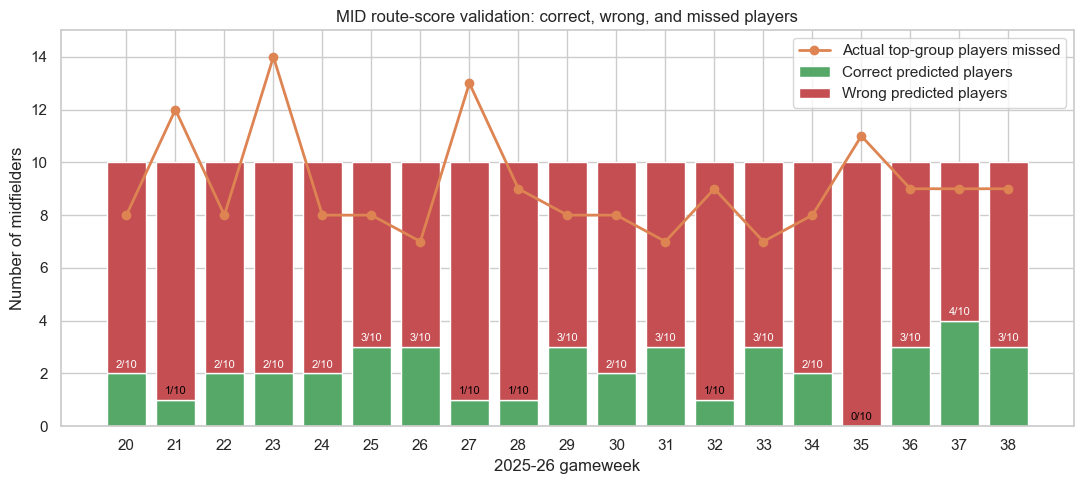

In [41]:
import matplotlib.pyplot as plt

midfielder_error_plot = midfielder_route_detail_df.copy()
midfielder_error_plot["wrong_predicted"] = (
    midfielder_error_plot["n_pred"] - midfielder_error_plot["n_correct"]
)
midfielder_error_plot["missed_actual"] = (
    midfielder_error_plot["n_true"] - midfielder_error_plot["n_correct"]
)

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(
    midfielder_error_plot["GW"],
    midfielder_error_plot["n_correct"],
    color="#55A868",
    label="Correct predicted players",
)
ax.bar(
    midfielder_error_plot["GW"],
    midfielder_error_plot["wrong_predicted"],
    bottom=midfielder_error_plot["n_correct"],
    color="#C44E52",
    label="Wrong predicted players",
)
ax.plot(
    midfielder_error_plot["GW"],
    midfielder_error_plot["missed_actual"],
    color="#DD8452",
    marker="o",
    linewidth=2,
    label="Actual top-group players missed",
)
for row in midfielder_error_plot.itertuples(index=False):
    ax.text(
        row.GW,
        row.n_correct + 0.15,
        f"{row.n_correct}/10",
        ha="center",
        va="bottom",
        fontsize=8,
        color="white" if row.n_correct >= 2 else "black",
    )
ax.set_xticks(midfielder_error_plot["GW"])
ax.set_ylim(0, max(11, midfielder_error_plot["missed_actual"].max() + 1))
ax.set_xlabel("2025-26 gameweek")
ax.set_ylabel("Number of midfielders")
ax.set_title("MID route-score validation: correct, wrong, and missed players")
ax.legend(title="")
plt.tight_layout()
plt.show()


In [42]:
print("Choice weeks, 2025-26 GW20-38. Previous 3 weeks are already inside the fit:")
display(
    chosen_df[
        [
            "position",
            "model",
            "train_precision_at_k",
            "val_precision_at_k",
            "minutes_sort_precision_at_k",
        ]
    ]
)
print("Replay weeks, frozen model:")
display(
    replay_df.pivot(index="GW", columns="position", values="val_precision_at_k")
    .reindex(columns=position_order)
)


Choice weeks, 2025-26 GW20-38. Previous 3 weeks are already inside the fit:


,position,model,train_precision_at_k,val_precision_at_k,minutes_sort_precision_at_k
0,GK,minutes_sort,0.405848,0.384211,0.384211
1,DEF,logistic_regression,0.263158,0.257895,0.215789
2,MID,gradient_boosting,0.384211,0.200000,0.115789
3,FWD,logistic_regression,0.515789,0.526316,0.505263


Replay weeks, frozen model:


position,GK,DEF,MID,FWD
GW,,,,
1,0.400000,0.0,0.2,0.0
2,0.400000,0.1,0.4,0.3
3,0.200000,0.1,0.3,0.6
4,0.400000,0.5,0.2,0.4
5,0.428571,0.3,0.3,0.7
6,0.285714,0.2,0.4,0.3
7,0.428571,0.1,0.0,0.5
8,0.285714,0.2,0.2,0.8
9,0.428571,0.2,0.4,0.9


In [43]:
# test GW shortlists from the live fit. Ties at the cutoff stay in the list.
top_lists = {}
chosen_model = chosen_df.set_index("position")["model"]
for position, k in K_BY_POSITION.items():
    group = test_pred_df[test_pred_df["position"] == position]
    top_ids = top_ids_with_ties(group, "score", k)
    top_lists[position] = (
        group[group[id_column].isin(top_ids)]
        [[id_column, "name", "team", "position", "score", "value", "model"]]
        .sort_values(["score", "name"], ascending=[False, True])
        .reset_index(drop=True)
    )
    print(
        f"\n{position}: {chosen_model[position]}, target K={k}, "
        f"shortlist size={len(top_lists[position])} "
        f"(ties included, test GW {test_gw}, live fit)"
    )
    display(top_lists[position])



GK: minutes_sort, target K=5, shortlist size=7 (ties included, test GW 11, live fit)


,element,name,team,position,score,value,model
0,109,Verbruggen,Brighton,GK,92.056453,47,minutes_sort
1,384,Donnarumma,Man City,GK,91.478604,54,minutes_sort
2,57,Petrović,Bournemouth,GK,91.434438,45,minutes_sort
3,226,Pickford,Everton,GK,90.013102,55,minutes_sort
4,567,Horníček,Newcastle,GK,90.000000,50,minutes_sort
5,250,Leno,Fulham,GK,90.000000,45,minutes_sort
6,572,Tzolakis,Hull City,GK,90.000000,47,minutes_sort



DEF: logistic_regression, target K=10, shortlist size=10 (ties included, test GW 11, live fit)


,element,name,team,position,score,value,model
0,4,Gabriel,Arsenal,DEF,0.434905,81,logistic_regression
1,112,Van Hecke,Spurs,DEF,0.275936,51,logistic_regression
2,60,Hill,Bournemouth,DEF,0.273219,56,logistic_regression
3,61,Truffert,Bournemouth,DEF,0.265435,54,logistic_regression
4,566,Silva,Bournemouth,DEF,0.246719,51,logistic_regression
5,229,Tarkowski,Everton,DEF,0.244855,62,logistic_regression
6,503,Van de Ven,Spurs,DEF,0.244417,50,logistic_regression
7,356,Virgil,Liverpool,DEF,0.239169,64,logistic_regression
8,390,Rúben,Man City,DEF,0.235280,55,logistic_regression
9,115,De Cuyper,Brighton,DEF,0.223170,55,logistic_regression



MID: gradient_boosting, target K=10, shortlist size=10 (ties included, test GW 11, live fit)


,element,name,team,position,score,value,model
0,426,B.Fernandes,Man Utd,MID,0.347624,116,gradient_boosting
1,154,Palmer,Chelsea,MID,0.322843,98,gradient_boosting
2,627,Barcola,Liverpool,MID,0.227014,81,gradient_boosting
3,40,Rogers,Chelsea,MID,0.225074,82,gradient_boosting
4,124,Groß,Brighton,MID,0.217659,63,gradient_boosting
5,211,Yeremy,Crystal Palace,MID,0.190147,55,gradient_boosting
6,68,Tavernier,Bournemouth,MID,0.186156,67,gradient_boosting
7,542,E.Le Fée,Sunderland,MID,0.173940,57,gradient_boosting
8,13,Rice,Arsenal,MID,0.173218,75,gradient_boosting
9,512,Kudus,Spurs,MID,0.169615,66,gradient_boosting



FWD: logistic_regression, target K=10, shortlist size=10 (ties included, test GW 11, live fit)


,element,name,team,position,score,value,model
0,411,Haaland,Man City,FWD,0.861533,158,logistic_regression
1,79,Evanilson,Bournemouth,FWD,0.604030,65,logistic_regression
2,295,McBurnie,Hull City,FWD,0.572221,55,logistic_regression
3,106,Thiago,Brentford,FWD,0.571449,78,logistic_regression
4,346,Calvert-Lewin,Leeds,FWD,0.546464,60,logistic_regression
5,166,N.Jackson,Aston Villa,FWD,0.521710,71,logistic_regression
6,379,Isak,Liverpool,FWD,0.501130,93,logistic_regression
7,401,Marmoush,Spurs,FWD,0.475386,70,logistic_regression
8,569,Gonzalo,Fulham,FWD,0.473115,59,logistic_regression
9,465,Osula,Newcastle,FWD,0.471869,58,logistic_regression


### Plots

The bars are the 2025-26 choice. A fitted model is kept only when its bar beats the minutes sort. The line is the frozen replay on this season's finished weeks. The last chart is the live shortlist.


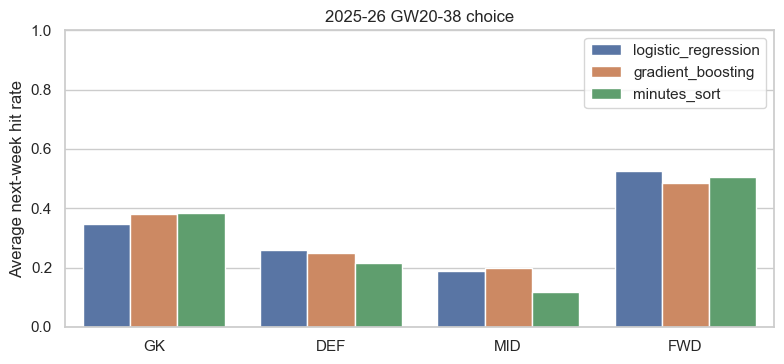

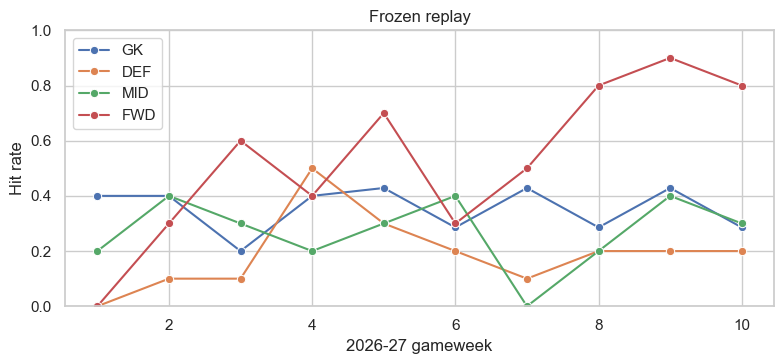

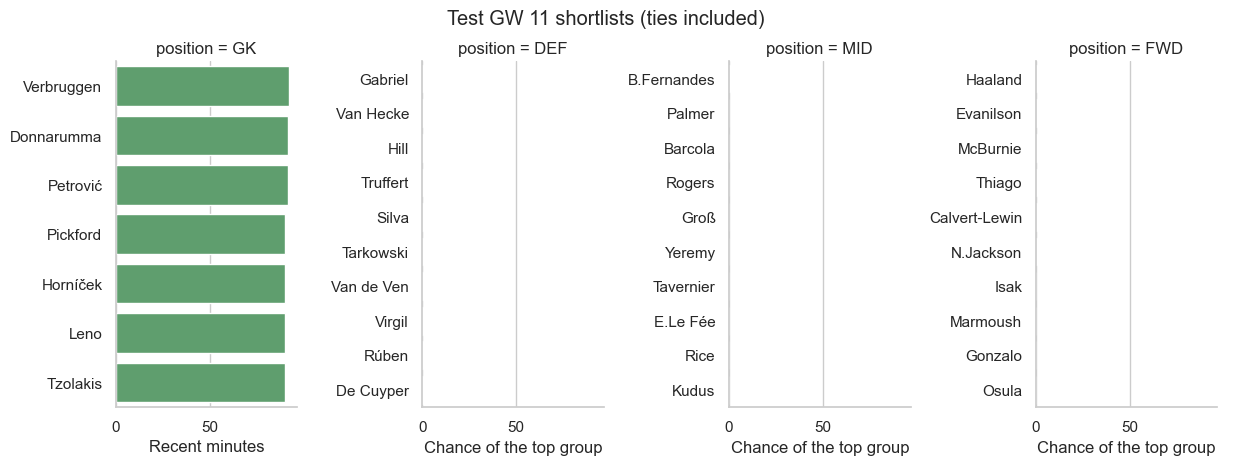

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
model_order = models_to_grade + [reference_name]
plot_results = results_df.copy()
plot_results["model"] = pd.Categorical(plot_results["model"], model_order, ordered=True)

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(
    data=plot_results,
    x="position",
    y="val_precision_at_k",
    hue="model",
    hue_order=model_order,
    order=position_order,
    ax=ax,
)
ax.set_ylim(0, 1)
ax.set_xlabel("")
ax.set_ylabel("Average next-week hit rate")
ax.set_title("2025-26 GW20-38 choice")
ax.legend(title="")
plt.tight_layout()
plt.show()

replay_plot = replay_df.copy()
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.lineplot(
    data=replay_plot,
    x="GW",
    y="val_precision_at_k",
    hue="position",
    hue_order=position_order,
    marker="o",
    ax=ax,
)
ax.set_ylim(0, 1)
ax.set_xlabel("2026-27 gameweek")
ax.set_ylabel("Hit rate")
ax.set_title("Frozen replay")
ax.legend(title="")
plt.tight_layout()
plt.show()

test_plot_df = pd.concat(top_lists.values(), ignore_index=True)
top_plot = (
    test_plot_df.sort_values("score", ascending=False)
    .groupby("position", group_keys=False)
    .head(10)
)
g = sns.catplot(
    data=top_plot,
    y="name",
    x="score",
    col="position",
    kind="bar",
    color="#55A868",
    sharey=False,
    height=4.5,
    aspect=0.7,
    col_order=position_order,
)
g.set_axis_labels("", "")
for position, ax in zip(position_order, g.axes.flat):
    if position == "GK":
        ax.set_xlabel("Recent minutes")
    else:
        ax.set_xlabel("Chance of the top group")
g.figure.suptitle(f"Test GW {test_gw} shortlists (ties included)", y=1.03)
plt.show()


### Position-research interface

The root exports its leak-safe player-gameweek feature panel for the dedicated position notebooks. This changes no model or selection result; it prevents the branches from duplicating and drifting away from the shared data construction.

In [45]:
position_research_path = "fpl_feature_panel.pkl"
panel.to_pickle(position_research_path)
print("Position-research panel:", position_research_path, panel.shape)

Position-research panel: fpl_feature_panel.pkl (63803, 95)
